In [1]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Analyzing 60 tick intervals (Williams fractals)...
Aggregated 23,033,489 ticks into 460,669 bars (50 tick)
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 153,556 bars (150 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 65,809 bars (350 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 51,185 bars (450 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 41,879 bars (550 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 35,436 bars (650 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 30,711 bars (750 tick)
Aggregated 2

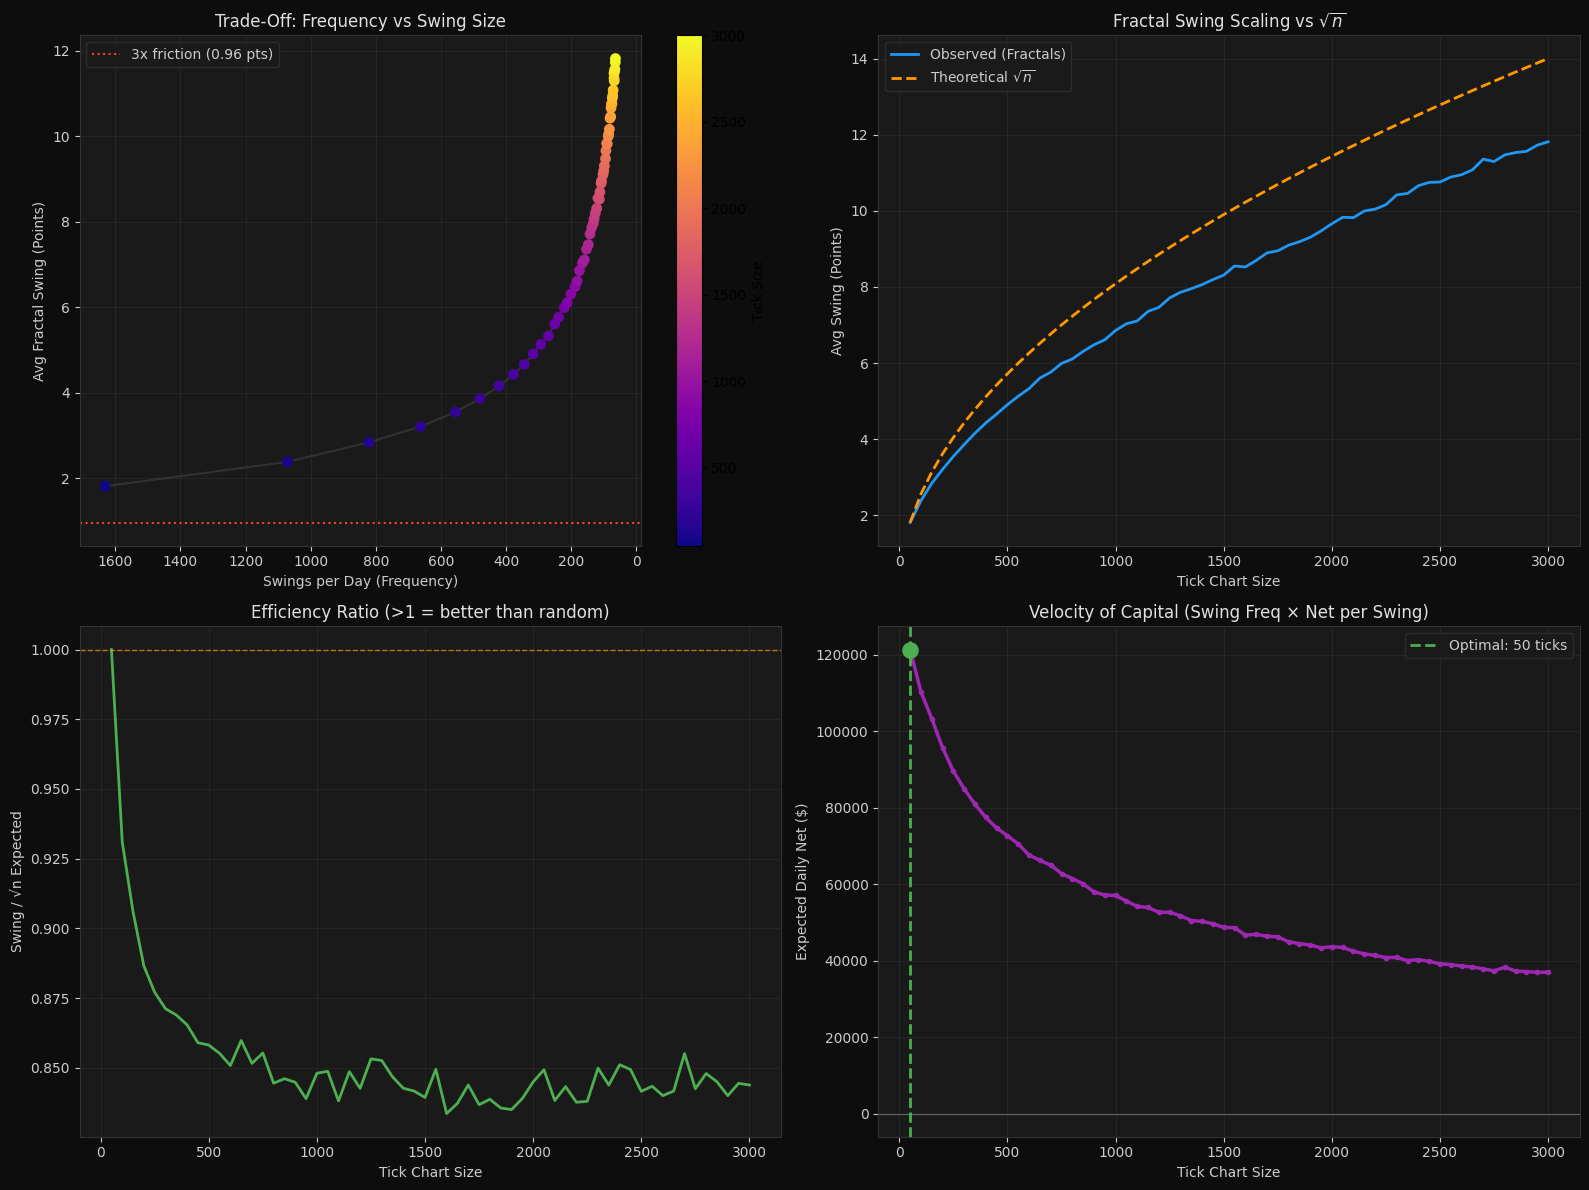


Optimal tick size by daily velocity: 50 ticks ($121,349/day)



Tick Size,Avg Swing (pts),Avg Swing ($),Swings/Day,Net/Swing ($),Daily Net ($)
50,1.808,$90.38,1631.4,$74.38,"$121,349"
100,2.380,$119.00,1071.0,$103.00,"$110,307"
150,2.836,$141.82,821.1,$125.82,"$103,312"
200,3.205,$160.25,663.1,$144.25,"$95,647"
250,3.545,$177.25,555.3,$161.25,"$89,550"
300,3.857,$192.87,480.1,$176.87,"$84,911"
350,4.156,$207.78,421.8,$191.78,"$80,886"
400,4.424,$221.22,377.3,$205.22,"$77,438"
450,4.658,$232.90,344.3,$216.90,"$74,672"
500,4.905,$245.26,316.8,$229.26,"$72,624"


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

td = TickData('./Data/ESTick.txt', timezone='America/Chicago')

# Parameters
start_tick = 50
end_tick = 3000
step_size = 50
tick_sizes = list(range(start_tick, end_tick + step_size, step_size))

# ES futures constants
friction_dollars = 16.00
point_value = 50.0


def williams_fractals(highs, lows, n=2):
    """Find Williams fractal swing points and return avg swing distance in points."""
    swing_prices = []
    swing_types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        # Swing high: high[i] > all n neighbors on both sides
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            swing_prices.append(highs[i])
            swing_types.append(1)
        # Swing low: low[i] < all n neighbors on both sides
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            swing_prices.append(lows[i])
            swing_types.append(-1)

    if len(swing_prices) < 2:
        return 0.0, 0

    # Distance between consecutive fractal points
    swings = np.abs(np.diff(swing_prices))
    return swings.mean(), len(swings)


results = []
print(f"Analyzing {len(tick_sizes)} tick intervals (Williams fractals)...")

for size in tick_sizes:
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()

    highs = df['High'].values
    lows = df['Low'].values

    avg_swing_pts, n_swings = williams_fractals(highs, lows, n=2)
    avg_swing_dollars = avg_swing_pts * point_value
    net_swing_dollars = avg_swing_dollars - friction_dollars

    total_days = len(np.unique(df.index.date))
    swings_per_day = n_swings / total_days if total_days > 0 else 0

    results.append({
        'tick_size': size,
        'avg_swing_pts': avg_swing_pts,
        'avg_swing_dollars': avg_swing_dollars,
        'net_per_swing': net_swing_dollars,
        'swings_per_day': swings_per_day,
        'daily_net': net_swing_dollars * swings_per_day,
        'n_swings': n_swings,
    })

results_df = pd.DataFrame(results)

# Theoretical sqrt(n) scaling (normalized to first valid point)
first_valid = results_df[results_df['avg_swing_pts'] > 0].iloc[0]
base_swing = first_valid['avg_swing_pts']
base_size = first_valid['tick_size']
theoretical_sqrt = base_swing * np.sqrt(results_df['tick_size'] / base_size)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555')

# 1) Frequency vs Avg Swing (the tradeoff curve)
ax = axes[0, 0]
sc = ax.scatter(results_df['swings_per_day'], results_df['avg_swing_pts'],
                c=results_df['tick_size'], cmap='plasma', s=60, edgecolor='none', zorder=5)
ax.plot(results_df['swings_per_day'], results_df['avg_swing_pts'],
        color='#555', linestyle='-', alpha=0.4, zorder=1)
min_viable_pts = (friction_dollars * 3) / point_value
ax.axhline(min_viable_pts, color='#f44336', linestyle=':', linewidth=1.5,
           label=f'3x friction ({min_viable_pts:.2f} pts)')
ax.set_xlabel('Swings per Day (Frequency)')
ax.set_ylabel('Avg Fractal Swing (Points)')
ax.set_title('Trade-Off: Frequency vs Swing Size')
ax.invert_xaxis()
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')
plt.colorbar(sc, ax=ax, label='Tick Size')

# 2) Avg swing vs theoretical sqrt(n)
ax = axes[0, 1]
ax.plot(results_df['tick_size'], results_df['avg_swing_pts'],
        color='#2196F3', linewidth=2, label='Observed (Fractals)')
ax.plot(results_df['tick_size'], theoretical_sqrt,
        color='#FF9800', linewidth=2, linestyle='--', label=r'Theoretical $\sqrt{n}$')
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Avg Swing (Points)')
ax.set_title(r'Fractal Swing Scaling vs $\sqrt{n}$')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

# 3) Efficiency ratio: actual swing / sqrt(n) expected
ax = axes[1, 0]
efficiency = results_df['avg_swing_pts'] / theoretical_sqrt
ax.plot(results_df['tick_size'], efficiency, color='#4CAF50', linewidth=2)
ax.axhline(1.0, color='#FF9800', linestyle='--', linewidth=1, alpha=0.7)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Swing / √n Expected')
ax.set_title('Efficiency Ratio (>1 = better than random)')

# 4) Daily net profit (velocity of capital)
ax = axes[1, 1]
ax.plot(results_df['tick_size'], results_df['daily_net'],
        color='#9C27B0', linewidth=2.5, marker='o', markersize=3)
ax.axhline(0, color='#666', linewidth=0.8)
optimal_idx = results_df['daily_net'].idxmax()
opt_tick = results_df.loc[optimal_idx, 'tick_size']
opt_val = results_df.loc[optimal_idx, 'daily_net']
ax.axvline(opt_tick, color='#4CAF50', linestyle='--', linewidth=2,
           label=f'Optimal: {opt_tick} ticks')
ax.scatter(opt_tick, opt_val, color='#4CAF50', s=120, zorder=5)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Expected Daily Net ($)')
ax.set_title('Velocity of Capital (Swing Freq × Net per Swing)')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'='*70}")
print(f"Optimal tick size by daily velocity: {opt_tick} ticks (${opt_val:,.0f}/day)")
print(f"{'='*70}\n")
top = results_df.nlargest(10, 'daily_net')[['tick_size', 'avg_swing_pts', 'avg_swing_dollars', 'swings_per_day', 'net_per_swing', 'daily_net']]
top.columns = ['Tick Size', 'Avg Swing (pts)', 'Avg Swing ($)', 'Swings/Day', 'Net/Swing ($)', 'Daily Net ($)']
display(top.style.format({
    'Avg Swing (pts)': '{:.3f}',
    'Avg Swing ($)': '${:.2f}',
    'Swings/Day': '{:.1f}',
    'Net/Swing ($)': '${:.2f}',
    'Daily Net ($)': '${:,.0f}',
}).hide(axis='index'))


Computing fractal distances for 30 tick sizes...
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 28,791 bars (800 tick)
Aggregated 23,033,489 ticks into 25,592 bars (900 tick)
Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Aggregated 23,033,489 ticks into 20,939 bars (1100 tick)
Aggregated 23,033,489 ticks into 19,194 bars (1200 tick)
Aggregated 23,033,489 ticks into 17,718 bars (1300 tick)
Aggregated 23,033,489 ticks into 16,452 bars (1400 tick)
Aggregated 23,033,489 ticks into 15,355 bars (1500 tick)
Aggregated 23,033,489 ticks into 14,395 bars (1600 tick)
Aggregated 23,033,489 ticks into 13,549 bars (

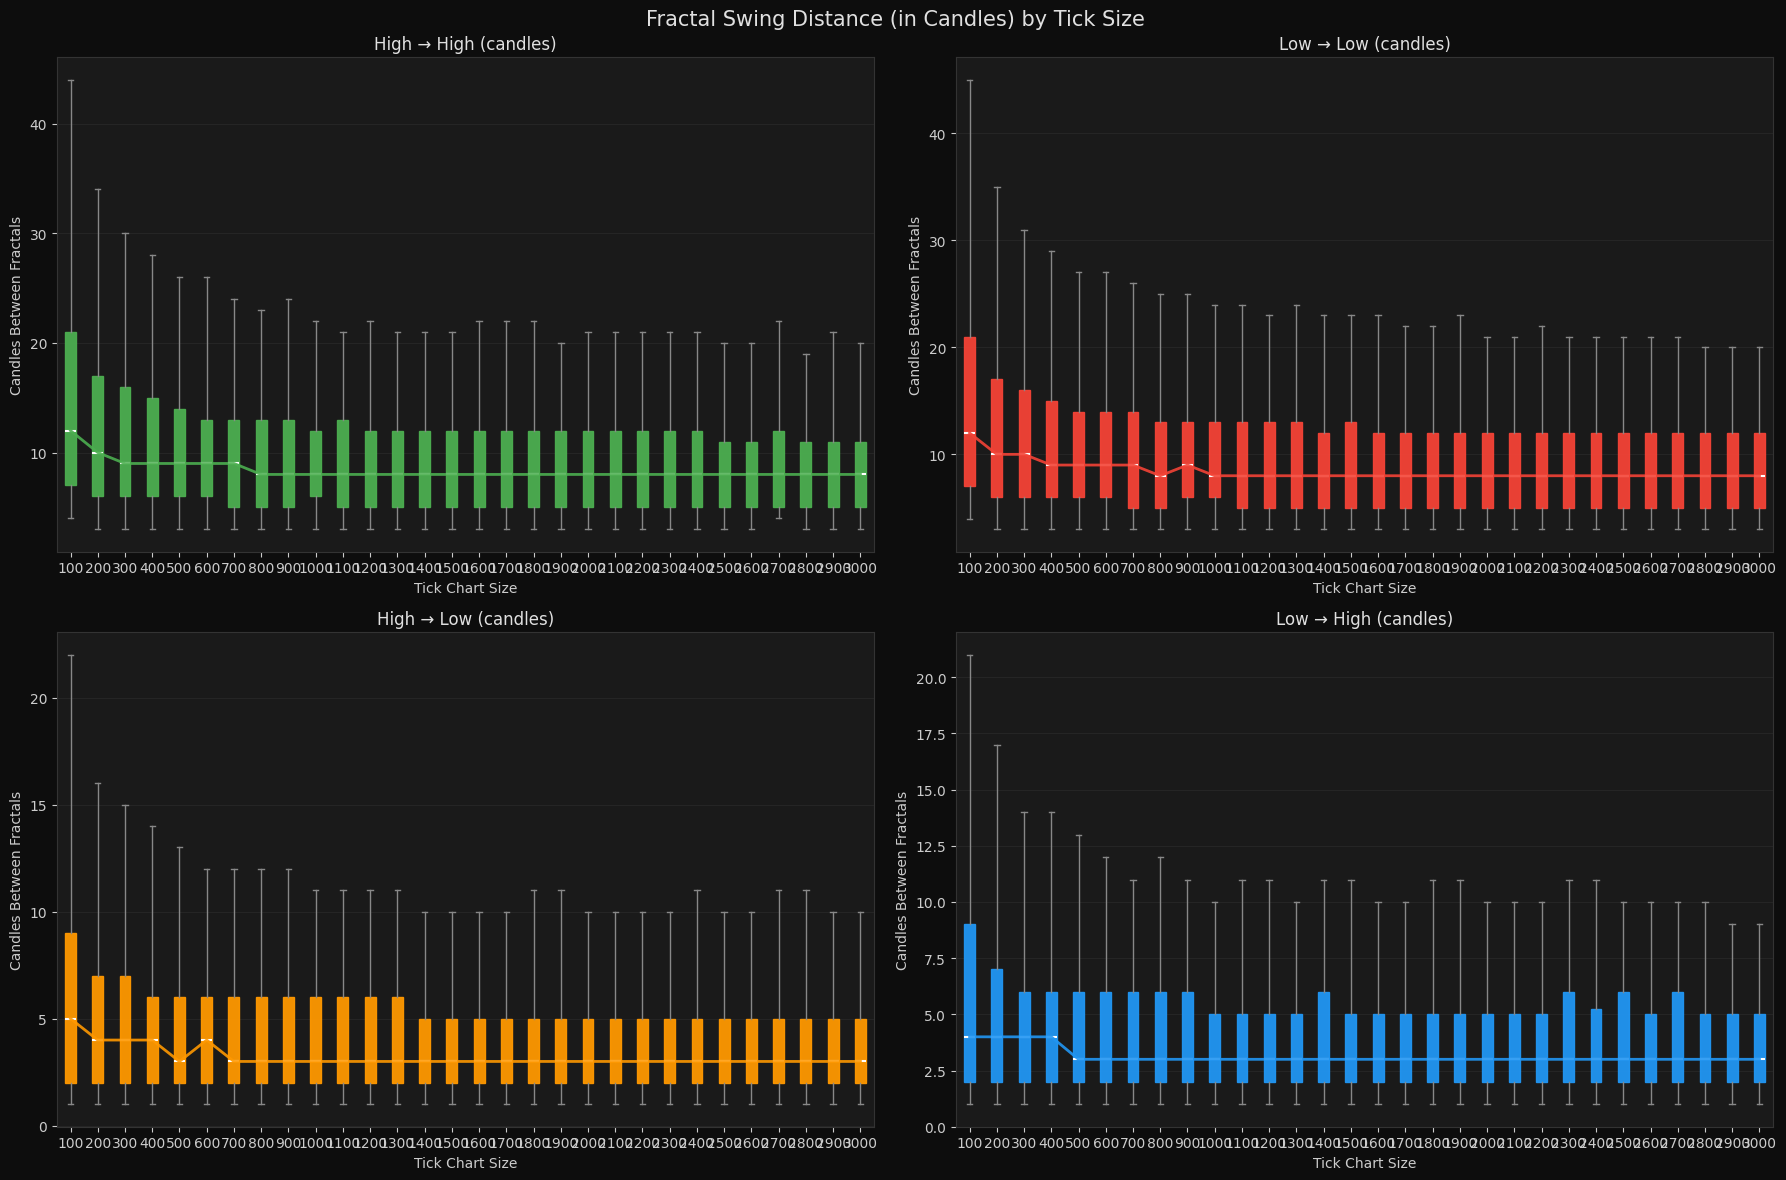

In [ ]:
def williams_fractals_detailed(highs, lows, n=2):
    """Return bar indices and types for all fractal points."""
    indices = []
    types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(1)
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(-1)

    return np.array(indices), np.array(types)


# Subset of tick sizes for readability on box plots
tick_sizes_box = list(range(100, 3001, 100))

high_to_high_data = {}
low_to_low_data = {}
high_to_low_data = {}
low_to_high_data = {}

print(f"Computing fractal distances for {len(tick_sizes_box)} tick sizes...")

for size in tick_sizes_box:
    
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()
    highs = df['High'].values
    lows = df['Low'].values

    frac_idx, frac_type = williams_fractals_detailed(highs, lows, n=2)
    if len(frac_idx) < 3:
        continue

    # Distances between consecutive same-type fractals
    high_indices = frac_idx[frac_type == 1]
    low_indices = frac_idx[frac_type == -1]

    if len(high_indices) > 1:
        high_to_high_data[size] = np.diff(high_indices)
    if len(low_indices) > 1:
        low_to_low_data[size] = np.diff(low_indices)

    # Distances between alternating types (high→low, low→high)
    h2l = []
    l2h = []
    for i in range(len(frac_idx) - 1):
        dist = frac_idx[i + 1] - frac_idx[i]
        if frac_type[i] == 1 and frac_type[i + 1] == -1:
            h2l.append(dist)
        elif frac_type[i] == -1 and frac_type[i + 1] == 1:
            l2h.append(dist)

    if h2l:
        high_to_low_data[size] = np.array(h2l)
    if l2h:
        low_to_high_data[size] = np.array(l2h)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle('Fractal Swing Distance (in Candles) by Tick Size', color='#e0e0e0', fontsize=15, y=0.98)

datasets = [
    (high_to_high_data, 'High → High (candles)', '#4CAF50'),
    (low_to_low_data, 'Low → Low (candles)', '#f44336'),
    (high_to_low_data, 'High → Low (candles)', '#FF9800'),
    (low_to_high_data, 'Low → High (candles)', '#2196F3'),
]

for ax, (data_dict, title, color) in zip(axes.flat, datasets):
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555', axis='y')

    sizes = sorted(data_dict.keys())
    box_data = [data_dict[s] for s in sizes]

    bp = ax.boxplot(box_data, positions=sizes, widths=40, patch_artist=True,
                    showfliers=False, whis=(5, 95),
                    medianprops=dict(color='white', linewidth=1.5),
                    whiskerprops=dict(color='#888'),
                    capprops=dict(color='#888'))

    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
        patch.set_edgecolor(color)

    # Overlay median line
    medians = [np.median(data_dict[s]) for s in sizes]
    ax.plot(sizes, medians, color=color, linewidth=2, alpha=0.9, zorder=5)

    ax.set_xlabel('Tick Chart Size')
    ax.set_ylabel('Candles Between Fractals')
    ax.set_title(title)
    ax.set_xlim(50, 3050)

plt.tight_layout()
plt.show()


In [35]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData

# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=200000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 115 bars (200000 tick)
Bars: 115
Date range: 2026-02-02 08:25:26.005800-06:00 to 2026-03-02 06:01:09.006560-06:00


In [2]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.special import gamma

def compute_ambe_hurst(X, delta, q=1, k=1):
    """
    Absolute Moments Based Estimator (AMBE) mirroring the provided paper logic.
    Computes rolling Hurst efficiently using a single lag and theoretical moments.
    """
    X = np.asarray(X)
    n = len(X)
    hurst_estimates = np.full(n, np.nan)
    
    # Normalization constant from the image
    K_k = (2**(k/2) * gamma((k+1)/2)) / np.sqrt(np.pi)
    
    # Loop over the rolling window
    for i in range(delta, n):
        window = X[i - delta : i + 1]
        
        # Compute k-th absolute moment of increments for the single lag 'q'
        diffs = np.abs(window[q:] - window[:-q])
        
        # Tick data can stall; avoid exact zeros to prevent log(0)
        if np.all(diffs == 0):
            hurst_estimates[i] = 0.5 # Default to random walk if completely flat
            continue
            
        S_k = np.mean(diffs**k)
        
        # Replicating the image's exact numerator/denominator math
        term_1 = np.sqrt(np.pi) * S_k
        term_2 = (2**(k/2)) * gamma((k+1)/2) * K_k
        numerator = np.log(term_1 / term_2)
        
        # Note: the image uses 'n' here, but in a rolling context, 
        # the effective sample size of the interval is 'delta'
        denominator = k * np.log((delta + 1) / q)
        
        H = - numerator / denominator
        hurst_estimates[i] = H
        
    return hurst_estimates

def ehlers_2_pole_supersmoother(data, period=10):
    """
    John Ehlers' 2-Pole SuperSmoother Filter.
    Effectively suppresses high-frequency noise/aliasing in the indicator.
    """
    a1 = np.exp(-np.pi * np.sqrt(2) / period)
    b1 = 2 * a1 * np.cos(np.pi * np.sqrt(2) / period)
    c2 = b1
    c3 = -a1**2
    c1 = 1 - c2 - c3
    
    smoothed = np.copy(data)
    
    for i in range(2, len(data)):
        if np.isnan(data[i]) or np.isnan(data[i-1]):
            continue
            
        # Handle initialization of prior values if they are nan
        prev1 = smoothed[i-1] if not np.isnan(smoothed[i-1]) else data[i]
        prev2 = smoothed[i-2] if not np.isnan(smoothed[i-2]) else data[i]
        
        term1 = c1 * (data[i] + data[i-1]) / 2.0
        smoothed[i] = term1 + c2 * prev1 + c3 * prev2
        
    return smoothed

# --- Execution ---
# Assuming 'close' is your raw tick price array
# close = np.random.randn(1000).cumsum() + 4000 # dummy data if needed

window_size = 30
lag_q = 1
moment_k = 2 # k=1 is standard for absolute moments, k=2 is variance

print(f"Calculating rolling AMBE Hurst Exponent (Window: {window_size}, q={lag_q}, k={moment_k})...")

# 1. Compute Raw Hurst
raw_hurst = compute_ambe_hurst(close, delta=window_size, q=lag_q, k=moment_k)

# 2. Shift to align signal (as in your original code)
# Using pandas just for the convenient shift method
shifted_hurst = pd.Series(raw_hurst).shift(-window_size).values

# 3. Apply Ehlers SuperSmoother to the shifted indicator
smoothed_hurst = ehlers_2_pole_supersmoother(shifted_hurst, period=10)

# Clean out bounds
smoothed_hurst = np.clip(smoothed_hurst, 0.0, 1.0)
x_axis = np.arange(len(close))

# --- Plotly Interactive Dashboard ---
fig = make_subplots(
    rows=2, cols=1, 
    shared_xaxes=True, 
    vertical_spacing=0.08,
    subplot_titles=("ES Futures Tick Price", f"AMBE Hurst w/ Ehlers Filter (Window: {window_size})"),
    row_heights=[0.6, 0.4]
)

# Top Plot: Close Price
fig.add_trace(
    go.Scatter(x=x_axis, y=close, mode='lines', name='Price', line=dict(color='#2c3e50', width=1.5)),
    row=1, col=1
)

# Bottom Plot: Raw Hurst (Faded)
fig.add_trace(
    go.Scatter(x=x_axis, y=shifted_hurst, mode='lines', name='Raw AMBE Hurst', 
               line=dict(color='rgba(142, 68, 173, 0.3)', width=1)),
    row=2, col=1
)

# Bottom Plot: Smoothed Hurst (Prominent)
fig.add_trace(
    go.Scatter(x=x_axis, y=smoothed_hurst, mode='lines', name='Smoothed Hurst', 
               line=dict(color='#8e44ad', width=2)),
    row=2, col=1
)

# Reference line at H = 0.5
fig.add_shape(
    type="line", x0=x_axis[0], y0=0.5, x1=x_axis[-1], y1=0.5,
    line=dict(color="black", width=1.5, dash="dash"), row=2, col=1
)

# Shading Zones
fig.add_hrect(y0=0.0, y1=0.5, fillcolor="rgba(39, 174, 96, 0.08)", layer="below", line_width=0, row=2, col=1)
fig.add_hrect(y0=0.5, y1=1.0, fillcolor="rgba(192, 57, 43, 0.08)", layer="below", line_width=0, row=2, col=1)

# Layout Configuration
fig.update_layout(
    height=800,
    showlegend=True,
    hovermode='x unified',
    template='plotly_white',
    margin=dict(l=60, r=30, t=50, b=50)
)

fig.update_yaxes(title_text="Price ($)", row=1, col=1)
fig.update_yaxes(title_text="Hurst (H)", range=[0, 1], row=2, col=1)
fig.update_xaxes(title_text="Tick", row=2, col=1)
fig.update_xaxes(matches='x')

fig.show()

Calculating rolling AMBE Hurst Exponent (Window: 30, q=1, k=2)...


NameError: name 'close' is not defined

In [ ]:
import numpy as np
import pandas as pd
import emd
import time
from IPython.display import clear_output
from Engine.TickData import TickData

# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
close = ohlc[:, 3]
df = pd.DataFrame({'Close': close})

MIN_WINDOW = 1000
PREDICTION_STEPS = 100
THRESHOLD = 0.5 

correct_predictions = 0
total_predictions = 0

print(f"Starting EMD Walk-Forward Analysis (using 'emd' library)...")
start_time = time.time()

for i in range(MIN_WINDOW, MIN_WINDOW + PREDICTION_STEPS):
    current_window = df['Close'].iloc[:i].values
    actual_next_close = df['Close'].iloc[i]
    
    # --- CORE EMD LOGIC (using 'emd' library) ---
    # The 'emd.sift.sift' function returns IMFs as (samples, imfs)
    # We take the first IMF (index 0)
    imfs = emd.sift.sift(current_window, max_imfs=3)
    current_imf1_state = imfs[-1, 0] 
    
    # Prediction logic
    actual_direction = "UP" if (actual_next_close - current_window[-1]) > 0 else "DOWN"
    prediction = "DOWN" if current_imf1_state > THRESHOLD else "UP"
    
    # Scoring
    if prediction == actual_direction:
        correct_predictions += 1
    total_predictions += 1
    
    if total_predictions % 5 == 0:
        clear_output(wait=True)
        print(f"Accuracy: {(correct_predictions / total_predictions) * 100:.2f}%")
        print(f"Last IMF1 State: {current_imf1_state:.3f}")

print(f"\nFinal Accuracy: {(correct_predictions / total_predictions) * 100:.2f}%")

Accuracy: 42.00%
Last IMF1 State: -0.886

Final Accuracy: 42.00%

Final Accuracy: 42.00%

Final Accuracy: 42.00%



>>> TESTING 250-TICK CHART <<<

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Evaluating Critical Period: 1500


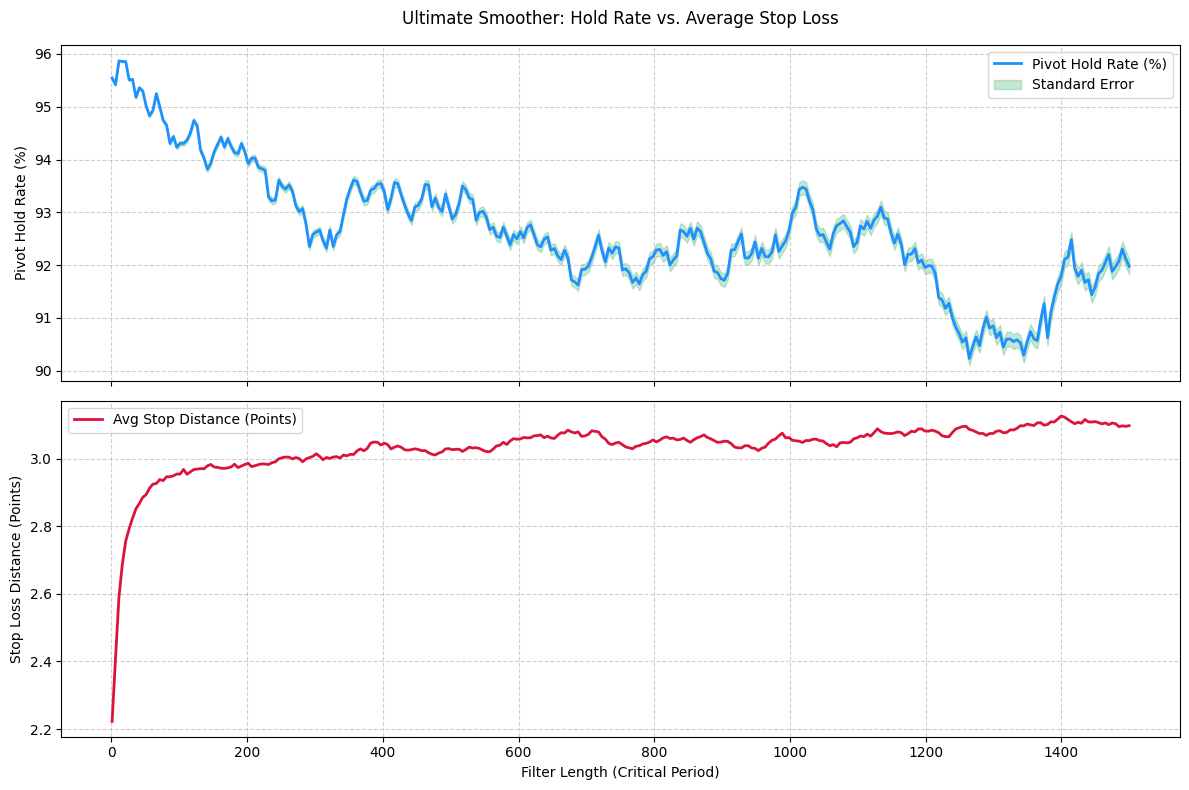

In [ ]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData

def ultimate_smoother(prices, critical_period=250):
    prices = np.array(prices)
    n = len(prices)

    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0

    filt = np.zeros(n)

    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = (
                (1.0 - c1) * prices[i]
                + (2.0 * c1 - c2) * prices[i-1]
                - (c1 + c3) * prices[i-2]
                + c2 * filt[i-1]
                + c3 * filt[i-2]
            )
    return filt

def evaluate_smoother_ev(df, critical_period=50, friction_points=0.58):
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n = len(closes)
    if n < critical_period + 10:
        print(f"Error: Not enough data. Found {n} bars.")
        return None, None, None

    filt = ultimate_smoother(closes, critical_period)

    current_state = None
    active_pivot_price = None
    run_violated = False
    entry_price = None
    
    # Trade tracking
    trades = []

    for i in range(1, n):
        # 1. Determine tick color
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            continue

        # --- Check violation for the ACTIVE trade using current candle BEFORE closing it ---
        if active_pivot_price is not None and not run_violated and current_state is not None:
            if current_state == 'red' and highs[i] > active_pivot_price:
                run_violated = True
            elif current_state == 'green' and lows[i] < active_pivot_price:
                run_violated = True

        # 2. Did the state flip?
        if current_state != tick_state:
            
            # A. Close out the PREVIOUS trade if one was active
            if current_state is not None:
                exit_price = closes[i]
                
                if current_state == 'red':  # We were SHORT
                    risk = active_pivot_price - entry_price
                    if run_violated:
                        gross_pnl = -risk  # Stopped out at pivot
                    else:
                        gross_pnl = entry_price - exit_price  # Rode it to the flip
                        
                elif current_state == 'green':  # We were LONG
                    risk = entry_price - active_pivot_price
                    if run_violated:
                        gross_pnl = -risk  # Stopped out at pivot
                    else:
                        gross_pnl = exit_price - entry_price  # Rode it to the flip
                
                net_pnl = gross_pnl - friction_points
                
                trades.append({
                    'state': current_state,
                    'held': not run_violated,
                    'risk': risk,
                    'gross_pnl': gross_pnl,
                    'net_pnl': net_pnl
                })

            # B. Setup the NEW trade
            if tick_state == 'red':
                active_pivot_price = max(highs[i-1], highs[i]) + 0.75
                run_violated = False
                entry_price = closes[i]
                # Instantly check if the new transition candle already violates the new pivot
                if highs[i] > active_pivot_price:
                    run_violated = True
                    
            elif tick_state == 'green':
                active_pivot_price = min(lows[i-1], lows[i]) - 0.75
                run_violated = False
                entry_price = closes[i]
                # Instantly check if the new transition candle already violates the new pivot
                if lows[i] < active_pivot_price:
                    run_violated = True

        current_state = tick_state

    # 4. Process Results
    total_trades = len(trades)
    if total_trades == 0:
        return None, None, None

    held_trades = [t for t in trades if t['held']]
    
    # Calculate Hold Rate & Error
    hold_rate_pct = (len(held_trades) / total_trades) * 100
    std_error = np.std([t['net_pnl'] for t in trades]) / np.sqrt(total_trades) if total_trades > 0 else 0
    
    # Calculate Average Stop Loss Distance (Risk)
    avg_risk = np.mean([t['risk'] for t in trades])
    
    return hold_rate_pct, std_error, avg_risk

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    # Test 250 Tick
    print("\n>>> TESTING 250-TICK CHART <<<")
    td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    
    x = np.linspace(1, 1500, num=300)
    y_hold_rate = []
    std_errors = []
    y_avg_risk = []
    
    for i in x:
        i = int(i)
        if i % 50 == 0:
            print(f"Evaluating Critical Period: {i}")
            
        hold_pct, std_err, avg_risk = evaluate_smoother_ev(df_250, critical_period=i)
        
        y_hold_rate.append(hold_pct)
        std_errors.append(std_err)
        y_avg_risk.append(avg_risk)

    # Convert to numpy arrays for element-wise operations during plotting
    y_hold_rate = np.array(y_hold_rate)
    std_errors = np.array(std_errors)
    y_avg_risk = np.array(y_avg_risk)

    # Create a 2-panel plot
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Top Plot: Hold Rate
    ax1.plot(x, y_hold_rate, color='dodgerblue', linewidth=2, label='Pivot Hold Rate (%)')
    ax1.fill_between(x, y_hold_rate - std_errors, y_hold_rate + std_errors, color='mediumseagreen', alpha=0.3, label='Standard Error')
    ax1.set_title('Ultimate Smoother: Hold Rate vs. Average Stop Loss', pad=15)
    ax1.set_ylabel('Pivot Hold Rate (%)')
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # Bottom Plot: Average Stop Loss Distance
    ax2.plot(x, y_avg_risk, color='crimson', linewidth=2, label='Avg Stop Distance (Points)')
    ax2.set_xlabel('Filter Length (Critical Period)')
    ax2.set_ylabel('Stop Loss Distance (Points)')
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend()

    plt.tight_layout()
    plt.show()


>>> TESTING N-FORWARD PIVOT HOLD RATES <<<
N=1 Candles Forward | Hold Rate: 98.78% | Sample Size: 6318
N=3 Candles Forward | Hold Rate: 90.16% | Sample Size: 6318
N=5 Candles Forward | Hold Rate: 81.28% | Sample Size: 6318
N=7 Candles Forward | Hold Rate: 74.61% | Sample Size: 6318
N=9 Candles Forward | Hold Rate: 69.03% | Sample Size: 6318
N=11 Candles Forward | Hold Rate: 65.07% | Sample Size: 6318
N=13 Candles Forward | Hold Rate: 61.58% | Sample Size: 6317
N=15 Candles Forward | Hold Rate: 58.33% | Sample Size: 6317
N=17 Candles Forward | Hold Rate: 55.59% | Sample Size: 6316
N=19 Candles Forward | Hold Rate: 53.42% | Sample Size: 6316
N=21 Candles Forward | Hold Rate: 51.41% | Sample Size: 6316
N=23 Candles Forward | Hold Rate: 49.60% | Sample Size: 6316
N=25 Candles Forward | Hold Rate: 47.79% | Sample Size: 6315
N=27 Candles Forward | Hold Rate: 46.28% | Sample Size: 6314
N=29 Candles Forward | Hold Rate: 45.04% | Sample Size: 6314
N=31 Candles Forward | Hold Rate: 43.58% | Sam

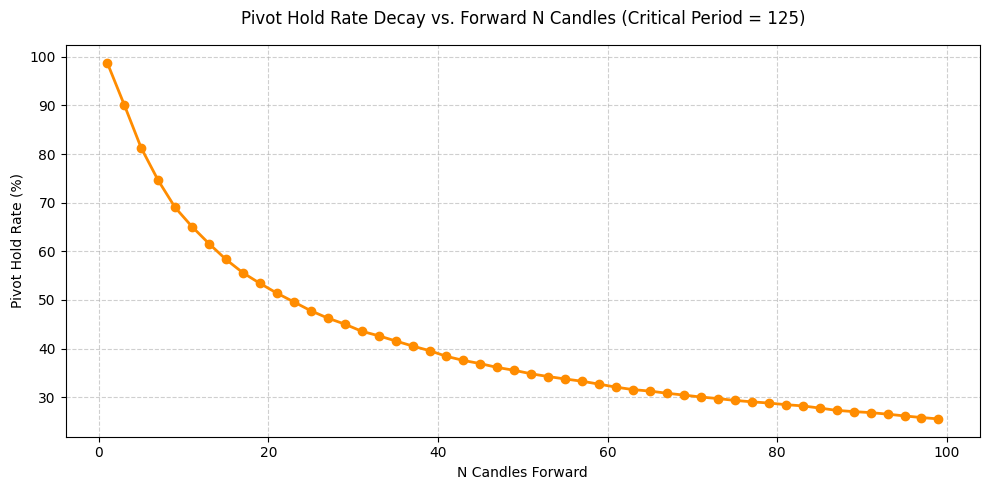

In [ ]:
def evaluate_forward_n_pivots(df, critical_period=50, n_forward=20, buffer=0.75):
    """
    Evaluates whether the Ultimate Smoother pivot point remains the absolute 
    high/low for a fixed forward window of n_forward candles.
    """
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n_bars = len(closes)
    if n_bars < critical_period + n_forward + 10:
        return None, None

    filt = ultimate_smoother(closes, critical_period)

    current_state = None
    evaluations = []

    # Stop loop early enough to allow n_forward lookahead
    for i in range(1, n_bars - n_forward):
        # 1. Determine filter slope state
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            current_state = tick_state
            continue

        # 2. Detect inflection point (Pivot)
        if current_state is not None and current_state != tick_state:
            
            if tick_state == 'green':
                # Bearish to Bullish -> Evaluate Bottom Pivot
                pivot_price = min(lows[i-1], lows[i]) - buffer
                
                # Check absolute low of the next n_forward candles
                forward_lows = lows[i+1 : i+1+n_forward]
                held = np.all(forward_lows >= pivot_price)
                evaluations.append(held)
                
            elif tick_state == 'red':
                # Bullish to Bearish -> Evaluate Top Pivot
                pivot_price = max(highs[i-1], highs[i]) + buffer
                
                # Check absolute high of the next n_forward candles
                forward_highs = highs[i+1 : i+1+n_forward]
                held = np.all(forward_highs <= pivot_price)
                evaluations.append(held)

        current_state = tick_state

    # 3. Process Results
    total_pivots = len(evaluations)
    if total_pivots == 0:
        return 0.0, 0
        
    held_count = sum(evaluations)
    hold_rate_pct = (held_count / total_pivots) * 100
    
    return hold_rate_pct, total_pivots

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    print("\n>>> TESTING N-FORWARD PIVOT HOLD RATES <<<")
    # td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    # df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    
    # Example execution sweeping the lookahead window (n_forward)
    critical_period_fixed = 125
    n_windows = np.arange(1, 100, 2) # Test 5 to 100 candles forward
    
    y_hold_rate = []
    
    for n in n_windows:
        hold_pct, total_pivots = evaluate_forward_n_pivots(
            df_250, 
            critical_period=critical_period_fixed, 
            n_forward=n, 
            buffer=0.75
        )
        y_hold_rate.append(hold_pct)
        print(f"N={n} Candles Forward | Hold Rate: {hold_pct:.2f}% | Sample Size: {total_pivots}")

    # Plot decay of hold rate over time
    plt.figure(figsize=(10, 5))import numpy as np
import pandas as pd

def evaluate_forward_n_pivots(df, critical_period=50, n_forward=20, std_multiplier=1.0):
    """
    Evaluates whether the Ultimate Smoother pivot point remains the absolute 
    high/low for a fixed forward window of n_forward candles, using a dynamic 
    buffer scaled to the volatility of the critical_period.
    """
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n_bars = len(closes)
    if n_bars < critical_period + n_forward + 10:
        return None, None

    filt = ultimate_smoother(closes, critical_period)
    
    # Vectorized calculation of rolling standard deviation matching the filter length
    rolling_std = pd.Series(closes).rolling(window=critical_period).std().values

    current_state = None
    evaluations = []

    # Start loop after critical_period to ensure valid standard deviation values
    start_idx = max(1, critical_period)
    
    for i in range(start_idx, n_bars - n_forward):
        # 1. Determine filter slope state
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            current_state = tick_state
            continue

        # 2. Detect inflection point (Pivot)
        if current_state is not None and current_state != tick_state:
            
            # Dynamically scale buffer to the period's measured volatility
            dynamic_buffer = rolling_std[i] * std_multiplier
            
            if np.isnan(dynamic_buffer):
                dynamic_buffer = 0.75 # Failsafe fallback
            
            if tick_state == 'green':
                # Bearish to Bullish -> Evaluate Bottom Pivot
                pivot_price = min(lows[i-1], lows[i]) - dynamic_buffer
                
                # Check absolute low of the next n_forward candles
                forward_lows = lows[i+1 : i+1+n_forward]
                held = np.all(forward_lows >= pivot_price)
                evaluations.append(held)
                
            elif tick_state == 'red':
                # Bullish to Bearish -> Evaluate Top Pivot
                pivot_price = max(highs[i-1], highs[i]) + dynamic_buffer
                
                # Check absolute high of the next n_forward candles
                forward_highs = highs[i+1 : i+1+n_forward]
                held = np.all(forward_highs <= pivot_price)
                evaluations.append(held)

        current_state = tick_state

    # 3. Process Results
    total_pivots = len(evaluations)
    if total_pivots == 0:
        return 0.0, 0
        
    held_count = sum(evaluations)
    hold_rate_pct = (held_count / total_pivots) * 100
    
    return hold_rate_pct, total_pivots

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    print("\n>>> TESTING N-FORWARD PIVOT HOLD RATES (DYNAMIC BUFFER) <<<")
    # td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    # df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    
    # Example execution sweeping the lookahead window (n_forward)
    critical_period_fixed = 125
    n_windows = np.arange(1, 100, 2) # Test 1 to 99 candles forward
    
    y_hold_rate = []
    
    for n in n_windows:
        hold_pct, total_pivots = evaluate_forward_n_pivots(
            df_250, 
            critical_period=critical_period_fixed, 
            n_forward=n, 
            std_multiplier=0.5 # Set multiplier instead of fixed points
        )
        y_hold_rate.append(hold_pct)
        print(f"N={n} Candles Forward | Hold Rate: {hold_pct:.2f}% | Sample Size: {total_pivots}")

    # Plot decay of hold rate over time
    plt.figure(figsize=(10, 5))
    plt.plot(n_windows, y_hold_rate, color='darkorange', linewidth=2, marker='o')
    plt.title(f'Dynamic Buffer Pivot Hold Rate vs. Forward N Candles\n(Critical Period = {critical_period_fixed}, Multiplier = 0.5x STD)', pad=15)
    plt.xlabel('N Candles Forward')
    plt.ylabel('Pivot Hold Rate (%)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
    plt.plot(n_windows, y_hold_rate, color='darkorange', linewidth=2, marker='o')
    plt.title(f'Pivot Hold Rate Decay vs. Forward N Candles (Critical Period = {critical_period_fixed})', pad=15)
    plt.xlabel('N Candles Forward')
    plt.ylabel('Pivot Hold Rate (%)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)


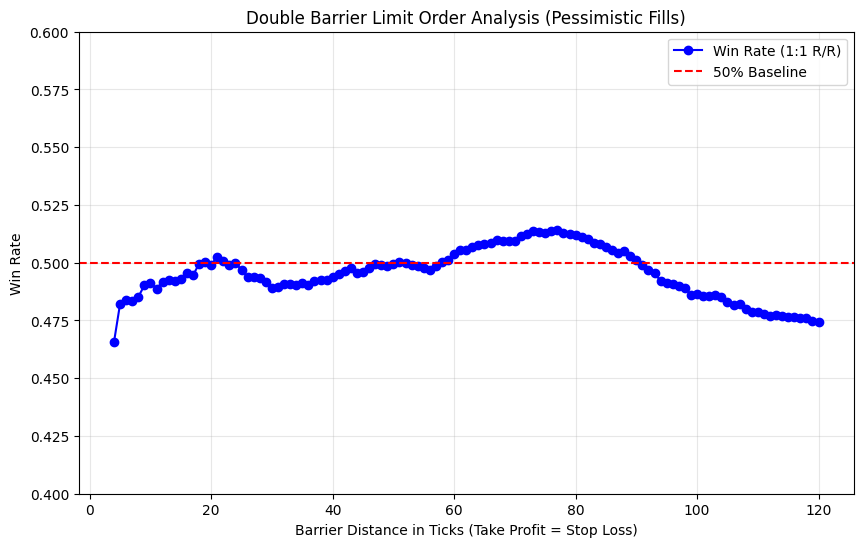

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Engine.TickData import TickData

def run_double_barrier_analysis(file_path, sample_size=10000, max_lookforward=10000):
    # Load 250-tick data
    # df = pd.read_csv(file_path) 
    
    # --- MOCK DATA GENERATION FOR DEMONSTRATION ---
    # Random walk using ES tick size
    td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    df = td_250.aggregate(method='tick', size=250).get_ohlc()
    # ----------------------------------------------
    
    tick_size = 0.25
    distances = np.arange(4, 121, 1) # 4 to 40 ticks
    win_rates = []

    # Select random indices for limit order placement
    # Ensure enough room at the end of the array for lookforward
    valid_max_idx = len(df) - max_lookforward
    entry_indices = np.random.randint(0, valid_max_idx, sample_size)
    
    highs = df[:, 1]
    lows = df[:, 2]
    closes_arr = df[:, 3]

    for d in distances:
        wins = 0
        losses = 0
        target_pts = d * tick_size
        
        for idx in entry_indices:
            entry_price = closes_arr[idx]
            
            # Extract forward window
            fwd_lows = lows[idx+1 : idx+max_lookforward]
            fwd_highs = highs[idx+1 : idx+max_lookforward]
            
            # PESSIMISTIC FILL: Must trade strictly below entry price
            fill_indices = np.where(fwd_lows < entry_price)[0]
            if len(fill_indices) == 0:
                continue # Order never filled
                
            fill_idx = fill_indices[0]
            
            # Post-fill price action
            post_fill_lows = fwd_lows[fill_idx:]
            post_fill_highs = fwd_highs[fill_idx:]
            
            tp_price = entry_price + target_pts
            sl_price = entry_price - target_pts
            
            # Find first touches of barriers
            tp_hits = np.where(post_fill_highs >= tp_price)[0]
            sl_hits = np.where(post_fill_lows <= sl_price)[0]
            
            if len(tp_hits) > 0 and len(sl_hits) > 0:
                if tp_hits[0] < sl_hits[0]:
                    wins += 1
                else:
                    losses += 1
            elif len(tp_hits) > 0:
                wins += 1
            elif len(sl_hits) > 0:
                losses += 1
                
        total_trades = wins + losses
        win_rate = (wins / total_trades) if total_trades > 0 else 0
        win_rates.append(win_rate)

    # Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(distances, win_rates, marker='o', linestyle='-', color='b', label='Win Rate (1:1 R/R)')
    plt.axhline(0.50, color='r', linestyle='--', label='50% Baseline')
    plt.title('Double Barrier Limit Order Analysis (Pessimistic Fills)')
    plt.xlabel('Barrier Distance in Ticks (Take Profit = Stop Loss)')
    plt.ylabel('Win Rate')
    plt.ylim(0.40, 0.60)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

run_double_barrier_analysis('es_250_tick.csv')

In [9]:
import pandas as pd

def compute_analytical_cutoff(delta_ticks=1, tolerances=[0.05, 0.02, 0.01, 0.005, 0.001]):
    """
    Computes the minimum barrier distance required to dilute adverse selection 
    to a specified tolerance level.
    
    delta_ticks: The adverse price movement required to secure a limit fill.
    tolerances: Acceptable deviation from the 50% baseline win rate.
    """
    results = []
    
    for epsilon in tolerances:
        # Solving the equation: epsilon = delta / (2 * d) -> d = delta / (2 * epsilon)
        min_distance = delta_ticks / (2 * epsilon)
        
        # Calculate resulting win rate
        win_rate = 0.5 - (delta_ticks / (2 * min_distance))
        
        results.append({
            'Acceptable Penalty': f"{epsilon*100:.2f}%",
            'Expected Win Rate': f"{win_rate:.4f}",
            'Min Barrier Distance (d) in Ticks': int(min_distance)
        })
        
    df = pd.DataFrame(results)
    return df

# Assuming a 1-tick adverse selection requirement for a pessimistic fill
print(compute_analytical_cutoff(delta_ticks=1).to_string(index=False))

Acceptable Penalty Expected Win Rate  Min Barrier Distance (d) in Ticks
             5.00%            0.4500                                 10
             2.00%            0.4800                                 25
             1.00%            0.4900                                 50
             0.50%            0.4950                                100
             0.10%            0.4990                                500


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Engine.TickData import TickData


def evaluate_random_baseline(df, n_samples=5000, stop_offset=0.75, median_duration=7):
    """
    Evaluates the probability of a pivot holding over a random streak duration.
    """
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
    else:
        highs = df[1].values
        lows = df[2].values

    n = len(highs)
    if n < 100:
        print("Insufficient data.")
        return

    # To achieve a median of 7 in an exponential distribution, the mean (scale) is Median / ln(2)
    scale_param = median_duration / np.log(2)
    
    # Generate random streak durations based on the distribution seen in image_8e00bc.png
    random_durations = np.random.exponential(scale=scale_param, size=n_samples).astype(int)
    # Ensure minimum duration of 1 to simulate at least the next bar
    random_durations = np.clip(random_durations, 1, None)
    
    # Generate random entry indices, ensuring we don't exceed array bounds
    max_start_idx = n - random_durations - 1
    valid_samples = max_start_idx > 1
    
    n_samples = np.sum(valid_samples)
    start_indices = np.random.randint(1, n - np.max(random_durations) - 1, size=n_samples)
    durations = random_durations[valid_samples]
    
    # Randomly assign long (1) or short (-1)
    directions = np.random.choice([1, -1], size=n_samples)
    
    held_count = 0
    
    for i in range(n_samples):
        start = start_indices[i]
        duration = durations[i]
        direction = directions[i]
        
        # Define the pivot based on the bar prior to entry, mimicking your logic
        if direction == 1: # Long
            pivot = lows[start - 1] - stop_offset
            # Check if any low during the streak goes below the pivot
            streak_lows = lows[start : start + duration]
            if np.min(streak_lows) >= pivot:
                held_count += 1
                
        else: # Short
            pivot = highs[start - 1] + stop_offset
            # Check if any high during the streak goes above the pivot
            streak_highs = highs[start : start + duration]
            if np.max(streak_highs) <= pivot:
                held_count += 1

    hold_rate = (held_count / n_samples) * 100
    std_error = np.sqrt((hold_rate/100 * (1 - hold_rate/100)) / n_samples) * 100

    print(">>> RANDOM BASELINE EVALUATION <<<")
    print(f"Total Samples: {n_samples}")
    print(f"Modeled Median Streak: {median_duration} bars")
    print(f"Static Stop Offset: {stop_offset}")
    print("-" * 30)
    print(f"Random Baseline Hold Rate: {hold_rate:.2f}% ± {std_error:.2f}%")
    
    return hold_rate

# ==========================================
# Execution Example
# ==========================================
if __name__ == "__main__":
    # Generate dummy OHLC data for demonstration (Replace with your df_250)
    # Drift = 0 (pure random walk)
    n_bars = 10000
    td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    # Run the baseline test
    evaluate_random_baseline(df_250, n_samples=10000, stop_offset=0.75, median_duration=7)


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
>>> RANDOM BASELINE EVALUATION <<<
Total Samples: 10000
Modeled Median Streak: 7 bars
Static Stop Offset: 0.75
------------------------------
Random Baseline Hold Rate: 53.99% ± 0.50%



>>> TESTING N-FORWARD PIVOT HOLD RATES (DYNAMIC BUFFER) <<<
15.818554978100934
15.792841231306403
15.722518669557287
14.213813147684665
10.26413572765754
10.100492459198342
10.089263689855205
9.9252742075202
9.895177805124415
9.81251022549951
9.031695830998189
5.808193710732065
5.781766846937062
5.703536933946246
4.531830853283158
4.452283768434762
4.445568389160846
4.438755456213389
4.37955693023723
3.9993605323605097
3.9790443482335087
3.9581004038698593
3.390921148759322
3.476007385203695
3.481754813794878
3.5047461472355885
3.8487069096026105
3.9017633726375456
3.9224048551879234
3.926910090441365
3.929276958176247
3.917349832973232
3.9202039435840543
3.528046538812786
3.4676145230560307
3.4614904221850713
3.4557200133652732
3.4497035892968912
3.3004926240446784
2.771515577983288
2.7127579794019634
2.4795828328464693
2.4741042649124427
2.2208522571137035
2.208849123795044
2.182131886432354
2.1435362273999243
2.137646677255819
2.1196404555155444
2.1183225066838838
2.115601535264729

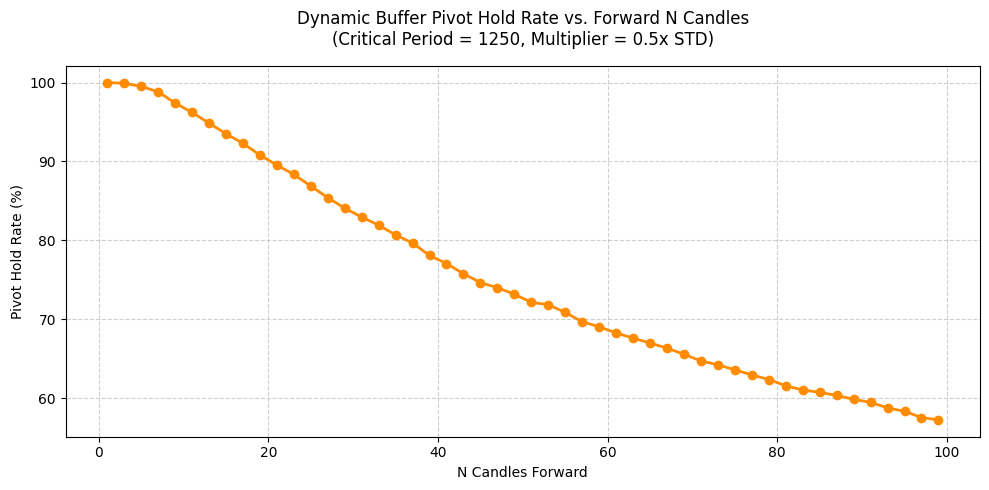

In [34]:
import numpy as np
import pandas as pd

def evaluate_forward_n_pivots(df, critical_period=50, n_forward=20, std_multiplier=1.0):
    """
    Evaluates whether the Ultimate Smoother pivot point remains the absolute 
    high/low for a fixed forward window of n_forward candles, using a dynamic 
    buffer scaled to the volatility of the critical_period.
    """
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n_bars = len(closes)
    if n_bars < critical_period + n_forward + 10:
        return None, None

    filt = ultimate_smoother(closes, critical_period)
    
    # Vectorized calculation of rolling standard deviation matching the filter length
    rolling_std = pd.Series(closes).rolling(window=critical_period).std().values

    current_state = None
    evaluations = []

    # Start loop after critical_period to ensure valid standard deviation values
    start_idx = max(1, critical_period)
    
    for i in range(start_idx, n_bars - n_forward):
        # 1. Determine filter slope state
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            current_state = tick_state
            continue

        # 2. Detect inflection point (Pivot)
        if current_state is not None and current_state != tick_state:
            
            # Dynamically scale buffer to the period's measured volatility
            dynamic_buffer = rolling_std[i] * std_multiplier
            print(dynamic_buffer)
            
            if np.isnan(dynamic_buffer):
                dynamic_buffer = 0.75 # Failsafe fallback
            
            if tick_state == 'green':
                # Bearish to Bullish -> Evaluate Bottom Pivot
                pivot_price = min(lows[i-1], lows[i]) - dynamic_buffer
                
                # Check absolute low of the next n_forward candles
                forward_lows = lows[i+1 : i+1+n_forward]
                held = np.all(forward_lows >= pivot_price)
                evaluations.append(held)
                
            elif tick_state == 'red':
                # Bullish to Bearish -> Evaluate Top Pivot
                pivot_price = max(highs[i-1], highs[i]) + dynamic_buffer
                
                # Check absolute high of the next n_forward candles
                forward_highs = highs[i+1 : i+1+n_forward]
                held = np.all(forward_highs <= pivot_price)
                evaluations.append(held)

        current_state = tick_state

    # 3. Process Results
    total_pivots = len(evaluations)
    if total_pivots == 0:
        return 0.0, 0
        
    held_count = sum(evaluations)
    hold_rate_pct = (held_count / total_pivots) * 100
    
    return hold_rate_pct, total_pivots

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    import matplotlib.pyplot as plt

    print("\n>>> TESTING N-FORWARD PIVOT HOLD RATES (DYNAMIC BUFFER) <<<")
    # td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    # df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    
    # Example execution sweeping the lookahead window (n_forward)
    critical_period_fixed = 1250
    n_windows = np.arange(1, 100, 2) # Test 1 to 99 candles forward
    
    y_hold_rate = []
    
    for n in n_windows:
        hold_pct, total_pivots = evaluate_forward_n_pivots(
            df_250, 
            critical_period=critical_period_fixed, 
            n_forward=n, 
            std_multiplier=0.5 # Set multiplier instead of fixed points
        )
        y_hold_rate.append(hold_pct)
        print(f"N={n} Candles Forward | Hold Rate: {hold_pct:.2f}% | Sample Size: {total_pivots}")

    # Plot decay of hold rate over time
    plt.figure(figsize=(10, 5))
    plt.plot(n_windows, y_hold_rate, color='darkorange', linewidth=2, marker='o')
    plt.title(f'Dynamic Buffer Pivot Hold Rate vs. Forward N Candles\n(Critical Period = {critical_period_fixed}, Multiplier = 0.5x STD)', pad=15)
    plt.xlabel('N Candles Forward')
    plt.ylabel('Pivot Hold Rate (%)')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

In [27]:
def check_slope_correlation(df, critical_period=50):
    if isinstance(df, np.ndarray):
        closes = df[:, 3]
    else:
        closes = df[3].values
        
    filt = ultimate_smoother(closes, critical_period)
    
    # Calculate daily/bar-by-bar changes
    slope = np.diff(filt)
    returns = np.diff(closes)
    
    # Align arrays (np.diff reduces length by 1)
    slope = slope[:-1] 
    returns = returns[1:]
    
    # 1. Pearson Correlation
    correlation = np.corrcoef(slope, returns)[0, 1]
    
    # 2. Conditional Mean Returns
    mask_up = slope > 0
    mask_down = slope <= 0
    
    mean_return_up = np.mean(returns[mask_up])
    mean_return_down = np.mean(returns[mask_down])
    
    # 3. Significance (Hit Rate of sign)
    # Are returns positive when slope is positive?
    hit_rate = np.mean((slope > 0) == (returns > 0)) * 100

    max_lag = 20
    for k in range(1, max_lag + 1):
        # Align slope of current bar with return of k-th future bar
        corr = np.corrcoef(slope[:-k], returns[k:])[0, 1]
        print(f"Lag {k}: {corr:.4f}")
    
    print(f"--- Statistics for Period {critical_period} ---")
    print(f"Pearson Correlation: {correlation:.4f}")
    print(f"Mean Return (Slope > 0): {mean_return_up:.4f}")
    print(f"Mean Return (Slope <= 0): {mean_return_down:.4f}")
    print(f"Directional Hit Rate: {hit_rate:.2f}%")
    
    return correlation, mean_return_up, mean_return_down

# Execution
if __name__ == "__main__":
    # Assuming df_250 exists from previous context
    # Sweep through various periods to see if correlation holds
    periods = np.arange(50, 1250, 50)
    for p in periods:
        check_slope_correlation(df_250, critical_period=p)



Lag 1: -0.0078
Lag 2: -0.0057
Lag 3: -0.0012
Lag 4: -0.0011
Lag 5: -0.0018
Lag 6: -0.0018
Lag 7: -0.0014
Lag 8: -0.0008
Lag 9: -0.0012
Lag 10: -0.0020
Lag 11: -0.0020
Lag 12: -0.0015
Lag 13: 0.0018
Lag 14: 0.0015
Lag 15: -0.0002
Lag 16: -0.0013
Lag 17: -0.0022
Lag 18: -0.0020
Lag 19: -0.0015
Lag 20: -0.0024
--- Statistics for Period 50 ---
Pearson Correlation: -0.0076
Mean Return (Slope > 0): -0.0068
Mean Return (Slope <= 0): 0.0035
Directional Hit Rate: 50.54%
Lag 1: -0.0077
Lag 2: -0.0074
Lag 3: -0.0028
Lag 4: -0.0022
Lag 5: -0.0033
Lag 6: -0.0035
Lag 7: -0.0027
Lag 8: -0.0021
Lag 9: -0.0025
Lag 10: -0.0030
Lag 11: -0.0031
Lag 12: -0.0025
Lag 13: 0.0010
Lag 14: -0.0001
Lag 15: -0.0011
Lag 16: -0.0017
Lag 17: -0.0032
Lag 18: -0.0031
Lag 19: -0.0019
Lag 20: -0.0027
--- Statistics for Period 100 ---
Pearson Correlation: -0.0062
Mean Return (Slope > 0): -0.0029
Mean Return (Slope <= 0): -0.0003
Directional Hit Rate: 50.58%
Lag 1: -0.0083
Lag 2: -0.0090
Lag 3: -0.0040
Lag 4: -0.0030
Lag 5

In [4]:
import numpy as np
import pandas as pd

def calculate_frama(highs, lows, closes, length=16):
    """
    Computes Ehlers' Fractal Adaptive Moving Average (FRAMA).
    Length must be an even integer.
    """
    n = len(closes)
    frama = np.zeros(n)
    
    half_length = length // 2
    
    for i in range(n):
        if i < length:
            frama[i] = closes[i]
            continue
            
        # N1: First half (older data)
        high1 = np.max(highs[i - length + 1 : i - half_length + 1])
        low1  = np.min(lows[i - length + 1 : i - half_length + 1])
        n1 = (high1 - low1) / half_length
        
        # N2: Second half (newer data)
        high2 = np.max(highs[i - half_length + 1 : i + 1])
        low2  = np.min(lows[i - half_length + 1 : i + 1])
        n2 = (high2 - low2) / half_length
        
        # N3: Full window
        high3 = np.max(highs[i - length + 1 : i + 1])
        low3  = np.min(lows[i - length + 1 : i + 1])
        n3 = (high3 - low3) / length
        
        # Fractal Dimension (D)
        # Add epsilon to prevent log(0) in mathematically flat arrays
        if n1 + n2 > 0 and n3 > 0:
            d = (np.log(n1 + n2) - np.log(n3)) / np.log(2)
        else:
            d = 1.0 
            
        # Dynamic Alpha
        alpha = np.exp(-4.6 * (d - 1.0))
        
        # Ehlers bounds alpha between 0.01 and 1.0
        alpha = np.clip(alpha, 0.01, 1.0)
        
        frama[i] = alpha * closes[i] + (1 - alpha) * frama[i-1]
        
    return frama

def evaluate_frama_correlation(df, length=16, max_lag=20):
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    frama = calculate_frama(highs, lows, closes, length)
    
    # Calculate bar-by-bar changes
    slope = np.diff(frama)
    returns = np.diff(closes)
    
    # 1. Immediate Expectancy (Lag 1)
    slope_current = slope[:-1] 
    returns_next = returns[1:]
    
    mask_up = slope_current > 0
    mask_down = slope_current <= 0
    
    mean_return_up = np.mean(returns_next[mask_up]) if np.any(mask_up) else 0
    mean_return_down = np.mean(returns_next[mask_down]) if np.any(mask_down) else 0
    hit_rate = np.mean((slope_current > 0) == (returns_next > 0)) * 100
    
    print(f"--- FRAMA ({length}) Immediate Expectancy ---")
    print(f"Mean Return (Slope > 0): {mean_return_up:.6f}")
    print(f"Mean Return (Slope <= 0): {mean_return_down:.6f}")
    print(f"Directional Hit Rate: {hit_rate:.2f}%")
    
    # 2. Cross-Correlation (Group Delay Profiling)
    print(f"\n--- FRAMA ({length}) Cross-Correlation Profile ---")
    
    for k in range(1, max_lag + 1):
        # Align slope of current bar with return of k-th future bar
        if len(slope) > k and len(returns) > k:
            corr = np.corrcoef(slope[:-k], returns[k:])[0, 1]
            print(f"Lag {k:02d}: {corr:.4f}")

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    # Assuming df_250 is defined in the workspace
    from Engine.TickData import TickData
    td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
    df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
    evaluate_frama_correlation(df_250, length=16, max_lag=20)
    pass


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
--- FRAMA (16) Immediate Expectancy ---
Mean Return (Slope > 0): -0.007741
Mean Return (Slope <= 0): 0.004434
Directional Hit Rate: 50.60%

--- FRAMA (16) Cross-Correlation Profile ---
Lag 01: -0.0002
Lag 02: -0.0193
Lag 03: -0.0103
Lag 04: -0.0014
Lag 05: 0.0004
Lag 06: 0.0052
Lag 07: -0.0017
Lag 08: -0.0010
Lag 09: 0.0002
Lag 10: 0.0038
Lag 11: 0.0037
Lag 12: -0.0012
Lag 13: -0.0043
Lag 14: -0.0063
Lag 15: -0.0019
Lag 16: 0.0047
Lag 17: 0.0028
Lag 18: -0.0075
Lag 19: -0.0008
Lag 20: -0.0033



>>> CALCULATING MFE DISTRIBUTION (Length 1250) <<<


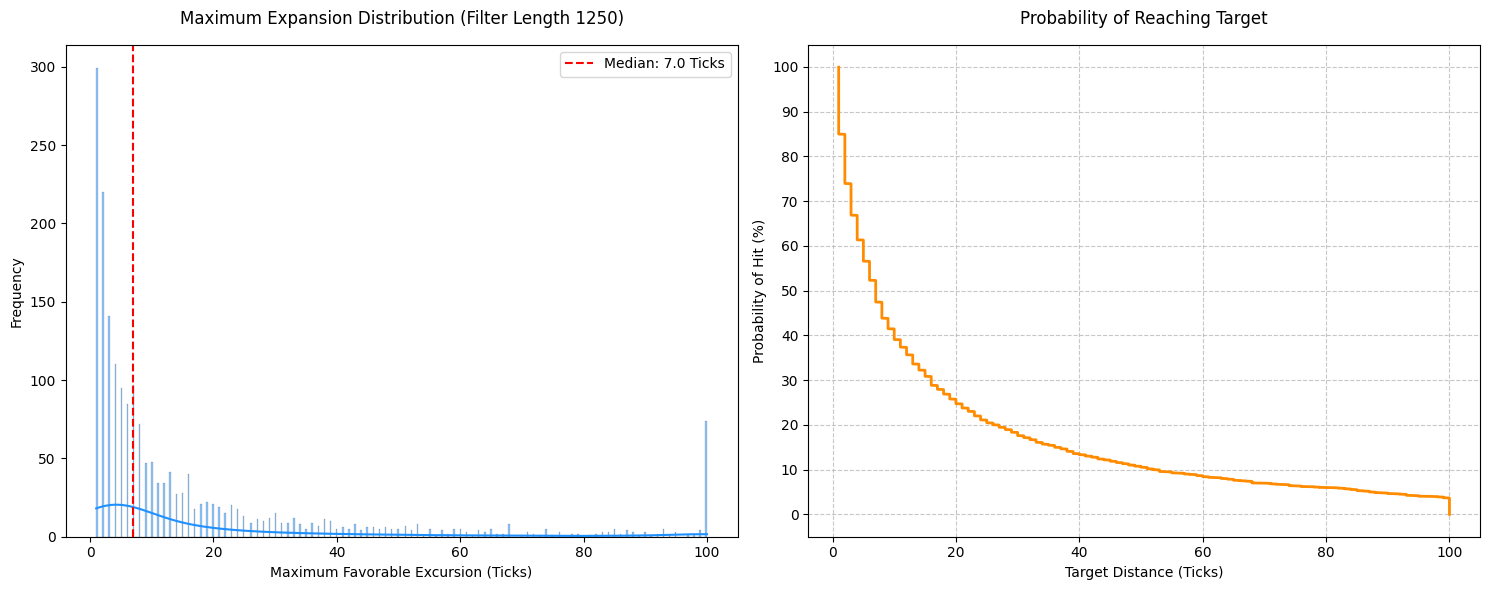

Total Filter Runs Evaluated: 1993
Median Run Expansion:        7.00 ticks
75th Percentile Expansion:   20.00 ticks

--- Probability of Reaching Specific Tick Targets ---
Target:  1 Ticks ( 0.25 pts) | Probability: 100.00%
Target:  2 Ticks ( 0.50 pts) | Probability: 85.00%
Target:  3 Ticks ( 0.75 pts) | Probability: 73.96%
Target:  4 Ticks ( 1.00 pts) | Probability: 66.88%
Target:  5 Ticks ( 1.25 pts) | Probability: 61.36%
Target:  6 Ticks ( 1.50 pts) | Probability: 56.60%
Target:  7 Ticks ( 1.75 pts) | Probability: 52.33%
Target:  8 Ticks ( 2.00 pts) | Probability: 47.47%
Target:  9 Ticks ( 2.25 pts) | Probability: 43.85%
Target: 10 Ticks ( 2.50 pts) | Probability: 41.50%
Target: 11 Ticks ( 2.75 pts) | Probability: 39.09%
Target: 12 Ticks ( 3.00 pts) | Probability: 37.38%
Target: 13 Ticks ( 3.25 pts) | Probability: 35.67%
Target: 14 Ticks ( 3.50 pts) | Probability: 33.62%
Target: 15 Ticks ( 3.75 pts) | Probability: 32.26%
Target: 16 Ticks ( 4.00 pts) | Probability: 30.86%
Target: 17 Ti

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Note: Assuming ultimate_smoother is imported or defined elsewhere in your environment.
# from Engine.TickData import TickData

def evaluate_smoother_expansion(df, critical_period=50, hysteresis=0.05):
    """
    Calculates the Maximum Favorable Excursion (MFE) in ticks for every
    regime state defined by the Ultimate Smoother, strictly enforcing
    chronological event sequencing.
    """
    if isinstance(df, np.ndarray):
        highs = df[:, 1]
        lows = df[:, 2]
        closes = df[:, 3]
    else:
        highs = df[1].values
        lows = df[2].values
        closes = df[3].values

    n = len(closes)
    if n < critical_period + 10:
        print(f"Error: Not enough data. Found {n} bars.")
        return None

    # Calculate the filter (ensure this function is in scope)
    filt = ultimate_smoother(closes, critical_period)

    current_state = None
    entry_price = None
    max_excursion_price = None
    
    expansions_ticks = []

    for i in range(1, n):
        # 1. Determine tick color
        if filt[i] > filt[i-1]:
            tick_state = 'green'
        elif filt[i] < filt[i-1]:
            tick_state = 'red'
        else:
            tick_state = current_state

        if tick_state is None:
            continue

        # 2. Did the state flip?
        if current_state != tick_state:
            
            # A. Close out the PREVIOUS state
            if current_state is not None:
                if current_state == 'green':  
                    max_excursion_price = max(max_excursion_price, highs[i])
                    expansion_pts = max_excursion_price - entry_price
                elif current_state == 'red':  
                    max_excursion_price = min(max_excursion_price, lows[i])
                    expansion_pts = entry_price - max_excursion_price
                
                expansions_ticks.append(expansion_pts * 4.0)
            
            # B. Setup the NEW state
            entry_price = closes[i]
            max_excursion_price = closes[i] 

        # 3. Monitor the maximum excursion while the state is active
        else:
            if current_state == 'green':
                max_excursion_price = max(max_excursion_price, highs[i])
            elif current_state == 'red':
                max_excursion_price = min(max_excursion_price, lows[i])

        current_state = tick_state

    # Remove negative expansions
    valid_expansions = [x for x in expansions_ticks if x > 0]
    
    return np.array(valid_expansions)

# ==========================================
# Execution Block & Visualization
# ==========================================
if __name__ == "__main__":
    # Assuming df_250 is defined in your environment
    test_length = 1250
    print(f"\n>>> CALCULATING MFE DISTRIBUTION (Length {test_length}) <<<")
    
    expansions = evaluate_smoother_expansion(df_250, critical_period=test_length)
    
    if expansions is not None and len(expansions) > 0:
        clip_max = 100 
        expansions_clipped = np.clip(expansions, 0, clip_max)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # --- PLOT 1: The Histogram (Density) ---
        sns.histplot(expansions_clipped, bins=400, kde=True, color='dodgerblue', ax=ax1)
        ax1.set_title(f'Maximum Expansion Distribution (Filter Length {test_length})', pad=15)
        ax1.set_xlabel('Maximum Favorable Excursion (Ticks)')
        ax1.set_ylabel('Frequency')
        ax1.axvline(np.median(expansions_clipped), color='red', linestyle='--', label=f'Median: {np.median(expansions_clipped):.1f} Ticks')
        ax1.legend()

        # --- PLOT 2: Target Probability Curve (Survival Function) ---
        x_sorted = np.sort(expansions_clipped)
        y_survival = 1.0 - np.arange(1, len(x_sorted) + 1) / len(x_sorted)
        
        ax2.plot(x_sorted, y_survival * 100, color='darkorange', linewidth=2)
        ax2.set_title('Probability of Reaching Target', pad=15)
        ax2.set_xlabel('Target Distance (Ticks)')
        ax2.set_ylabel('Probability of Hit (%)')
        ax2.grid(True, linestyle='--', alpha=0.7)
        ax2.set_yticks(np.arange(0, 101, 10))
        
        plt.tight_layout()
        plt.show(block=False) 
        
        # --- RAPID STATS ---
        total_runs = len(expansions)
        print(f"Total Filter Runs Evaluated: {total_runs}")
        print(f"Median Run Expansion:        {np.median(expansions):.2f} ticks")
        print(f"75th Percentile Expansion:   {np.percentile(expansions, 75):.2f} ticks\n")

        # --- EXACT TARGET PROBABILITIES ---
        print("--- Probability of Reaching Specific Tick Targets ---")
        targets_to_check = list(range(1, 21)) + [24, 28, 32, 40]
        
        for target in targets_to_check:
            successes = np.sum(expansions >= target)
            probability = (successes / total_runs) * 100
            print(f"Target: {target:2d} Ticks ({target/4.0:5.2f} pts) | Probability: {probability:5.2f}%")
            
        plt.show()


>>> CALCULATING STREAK DURATIONS (Length 250, No Hysteresis) <<<


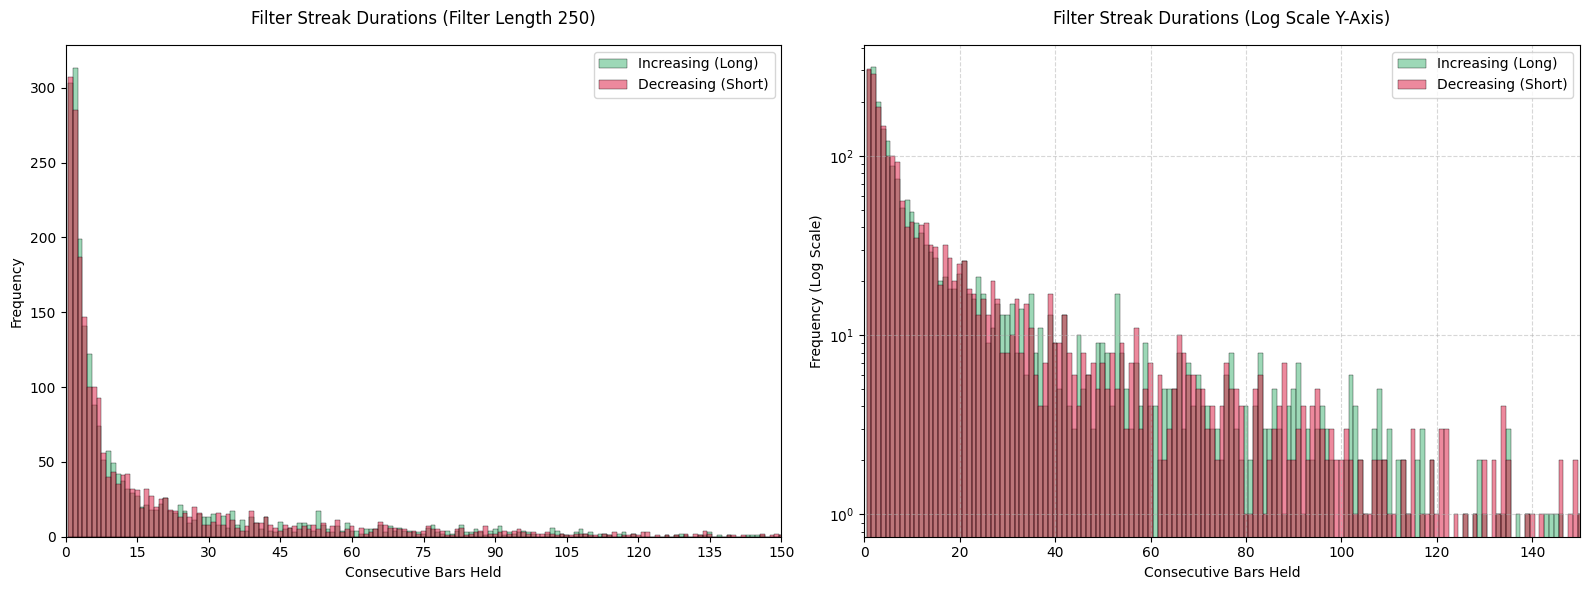

Total Increasing Streaks: 2289 | Median: 6.0 bars
Total Decreasing Streaks: 2288 | Median: 7.0 bars

--- Chop Analysis (Runs ending in 2 bars or less) ---
Increasing Chatter: 26.9% of all long signals are false flips.
Decreasing Chatter: 25.9% of all short signals are false flips.


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_streak_lengths(df, critical_period=250):
    """
    Calculates the consecutive bar duration of strictly increasing 
    vs. strictly decreasing filter states (Zero Hysteresis).
    """
    if isinstance(df, np.ndarray):
        closes = df[:, 3]
    else:
        closes = df[3].values

    n = len(closes)
    if n < critical_period + 10:
        print(f"Error: Not enough data. Found {n} bars.")
        return None, None

    # Calculate the filter (requires the ultimate_smoother function defined previously)
    filt = ultimate_smoother(closes, critical_period)

    increasing_streaks = []
    decreasing_streaks = []

    current_dir = None
    streak_len = 0

    for i in range(1, n):
        # 1. Determine strict mathematical slope (Zero Hysteresis)
        if filt[i] > filt[i-1]:
            tick_dir = 1
        elif filt[i] < filt[i-1]:
            tick_dir = -1
        else:
            tick_dir = current_dir # In the rare event of identical floats, maintain state

        if tick_dir is None:
            continue

        # 2. State Machine for Streak Counting
        if current_dir is None:
            current_dir = tick_dir
            streak_len = 1
        elif tick_dir == current_dir:
            # Continue the streak
            streak_len += 1
        else:
            # State flipped! Log the completed streak length
            if current_dir == 1:
                increasing_streaks.append(streak_len)
            else:
                decreasing_streaks.append(streak_len)
            
            # Reset the counter for the new direction
            current_dir = tick_dir
            streak_len = 1

    # Catch the final active streak when the loop ends
    if current_dir == 1:
        increasing_streaks.append(streak_len)
    elif current_dir == -1:
        decreasing_streaks.append(streak_len)

    return np.array(increasing_streaks), np.array(decreasing_streaks)

# ==========================================
# Execution Block & Visualization
# ==========================================
if __name__ == "__main__":
    # Assuming df_250 is already loaded from your TickData environment
    test_length = 250
    print(f"\n>>> CALCULATING STREAK DURATIONS (Length {test_length}, No Hysteresis) <<<")
    
    inc_streaks, dec_streaks = evaluate_streak_lengths(df_250, critical_period=test_length)
    
    if inc_streaks is not None and len(inc_streaks) > 0 and len(dec_streaks) > 0:
        # Determine the maximum streak to set our integer bins
        max_streak = int(max(np.max(inc_streaks), np.max(dec_streaks)))
        
        # We cap the visual X-axis at 150 bars just so the massive tail doesn't squish the chart,
        # but the bins are calculated strictly by 1-bar increments.
        plot_max = min(max_streak, 150)
        bins = np.arange(1, plot_max + 2) - 0.5 # -0.5 centers the bins perfectly over the integers

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        # --- PLOT 1: The Chatter Spike (Linear Scale) ---
        sns.histplot(inc_streaks, bins=bins, color='mediumseagreen', alpha=0.5, label='Increasing (Long)', ax=ax1)
        sns.histplot(dec_streaks, bins=bins, color='crimson', alpha=0.5, label='Decreasing (Short)', ax=ax1)
        
        ax1.set_title(f'Filter Streak Durations (Filter Length {test_length})', pad=15)
        ax1.set_xlabel('Consecutive Bars Held')
        ax1.set_ylabel('Frequency')
        ax1.set_xlim(0, plot_max)
        ax1.set_xticks(np.arange(0, plot_max + 1, step=max(1, plot_max//10)))
        ax1.legend()

        # --- PLOT 2: Log-Scale View (To see the surviving macro runs) ---
        # The chatter is so extreme it will dwarf the real trends. A log scale on the Y-axis reveals the hidden tail.
        sns.histplot(inc_streaks, bins=bins, color='mediumseagreen', alpha=0.5, label='Increasing (Long)', ax=ax2)
        sns.histplot(dec_streaks, bins=bins, color='crimson', alpha=0.5, label='Decreasing (Short)', ax=ax2)
        
        ax2.set_title('Filter Streak Durations (Log Scale Y-Axis)', pad=15)
        ax2.set_xlabel('Consecutive Bars Held')
        ax2.set_ylabel('Frequency (Log Scale)')
        ax2.set_yscale('log')
        ax2.set_xlim(0, plot_max)
        ax2.grid(True, linestyle='--', alpha=0.5)
        ax2.legend()
        
        plt.tight_layout()
        plt.show()
        
        # --- RAPID STATS ---
        print(f"Total Increasing Streaks: {len(inc_streaks)} | Median: {np.median(inc_streaks):.1f} bars")
        print(f"Total Decreasing Streaks: {len(dec_streaks)} | Median: {np.median(dec_streaks):.1f} bars")
        
        # Calculate exactly how much of the data is purely 1-bar or 2-bar "chatter"
        chatter_threshold = 2
        inc_chatter_pct = np.sum(inc_streaks <= chatter_threshold) / len(inc_streaks) * 100
        dec_chatter_pct = np.sum(dec_streaks <= chatter_threshold) / len(dec_streaks) * 100
        
        print(f"\n--- Chop Analysis (Runs ending in {chatter_threshold} bars or less) ---")
        print(f"Increasing Chatter: {inc_chatter_pct:.1f}% of all long signals are false flips.")
        print(f"Decreasing Chatter: {dec_chatter_pct:.1f}% of all short signals are false flips.")

Calculating filters and differences...


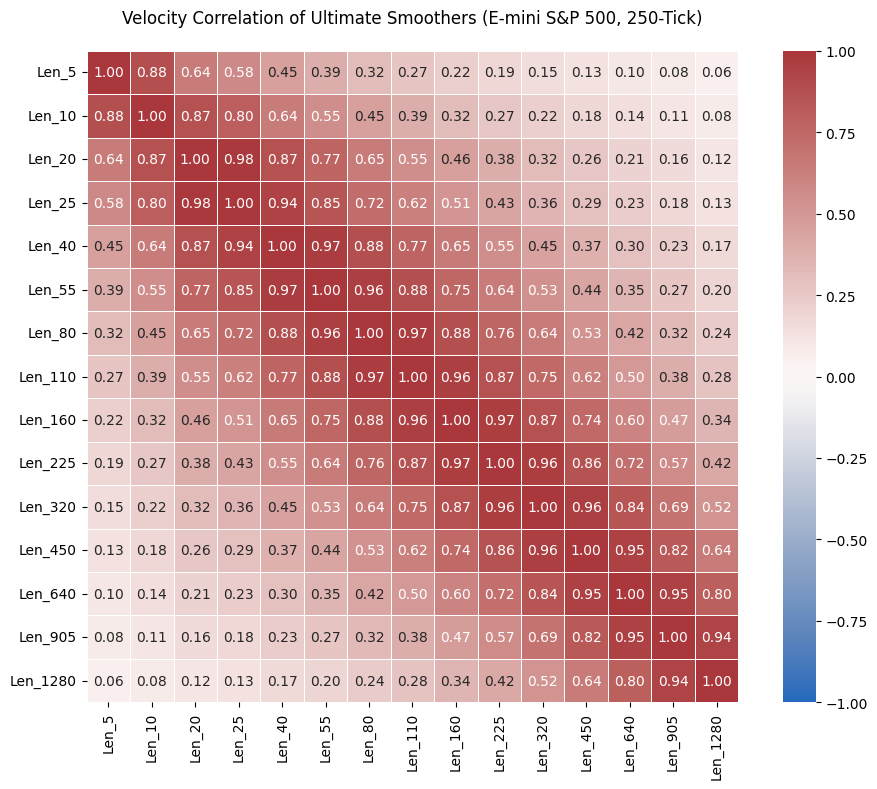

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_250 is already loaded from your previous execution block
closes = df_250[:, 3]

# 1. Generate the exponential lengths (Base 5, Multiplier 2)
# This will create: [5, 10, 20, 40, 80, 160, 320, 640, 1280]
num_lengths = 17
lengths = [5 * int(np.sqrt(2)**i) for i in range(num_lengths)]

# Dictionary to hold our differenced filter arrays
velocity_dict = {}

print("Calculating filters and differences...")
for length in lengths:
    # Generate the Ultimate Smoother for this length
    filt = ultimate_smoother(closes, critical_period=length)
    
    # Calculate the period-to-period difference (the slope/velocity)
    # prepending NaN keeps the array length consistent with the original data
    filt_diff = np.diff(filt, prepend=np.nan)
    
    # Store in dictionary with a clean column name
    velocity_dict[f'Len_{length}'] = filt_diff

# 2. Build the DataFrame and calculate the Pearson correlation matrix
df_velocities = pd.DataFrame(velocity_dict).dropna()
corr_matrix = df_velocities.corr()

# 3. Plot the Correlation Matrix
plt.figure(figsize=(10, 8))

# Use seaborn to create a heatmap
# vmin and vmax lock the color scale from -1 (perfect inverse) to 1 (perfect positive)
sns.heatmap(
    corr_matrix, 
    annot=True,          # Show the correlation numbers
    cmap='vlag',         # A clean blue-to-red diverging colormap
    fmt=".2f",           # Format to 2 decimal places
    vmin=-1, 
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(f"Velocity Correlation of Ultimate Smoothers (E-mini S&P 500, 250-Tick)", pad=20)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

<>:51: SyntaxWarning:

invalid escape sequence '\m'

<>:51: SyntaxWarning:

invalid escape sequence '\s'

<>:51: SyntaxWarning:

invalid escape sequence '\m'

<>:51: SyntaxWarning:

invalid escape sequence '\s'

C:\Users\ryany\AppData\Local\Temp\ipykernel_26996\3393239526.py:51: SyntaxWarning:

invalid escape sequence '\m'

C:\Users\ryany\AppData\Local\Temp\ipykernel_26996\3393239526.py:51: SyntaxWarning:

invalid escape sequence '\s'




Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)


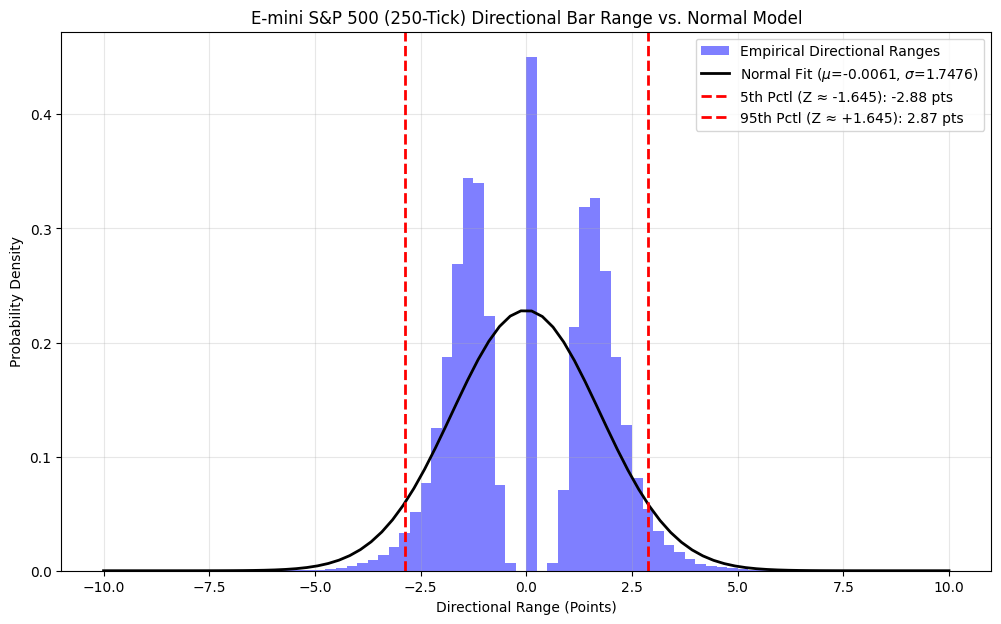

In [35]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData
import matplotlib.pyplot as plt
td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
# Assuming TickData is loaded as in your snippet
from Engine.TickData import TickData

td_250 = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df_250 = td_250.aggregate(method='tick', size=250).get_ohlc()

# Extract columns (Assuming Open=0, High=1, Low=2, Close=3)
opens = df_250[:, 0]
highs = df_250[:, 1]
lows = df_250[:, 2]
closes = df_250[:, 3]

# 1. Calculate the absolute size of the candle
candle_size = highs - lows

# 2. Determine the polarity (Bullish = +1, Bearish = -1, Doji = 0)
# np.sign returns -1 if x < 0, 0 if x==0, 1 if x > 0
polarity = np.sign(closes - opens)

# 3. Calculate Directional Excursion
directional_ranges = candle_size * polarity

# --- Statistical Fitting ---

# Fit a normal distribution to the directional ranges
mu, std = norm.fit(directional_ranges)

# Calculate the 90% Confidence Interval (5th and 95th percentiles)
ci_90_lower = norm.ppf(0.05, loc=mu, scale=std)
ci_90_upper = norm.ppf(0.95, loc=mu, scale=std)

# --- Plotting ---
plt.figure(figsize=(12, 7))

# Plot the empirical histogram of our new metric
count, bins, ignored = plt.hist(directional_ranges, bins=80, density=True, alpha=0.5, color='b', range=(-10, 10), label='Empirical Directional Ranges')

# Plot the theoretical PDF
x = np.linspace(-10, 10, 80)
pdf = norm.pdf(x, loc=mu, scale=std)
plt.plot(x, pdf, 'k-', linewidth=2, label=f'Normal Fit ($\mu$={mu:.4f}, $\sigma$={std:.4f})')

# Overlay the Confidence Intervals
plt.axvline(ci_90_lower, color='r', linestyle='dashed', linewidth=2, label=f'5th Pctl (Z ≈ -1.645): {ci_90_lower:.2f} pts')
plt.axvline(ci_90_upper, color='r', linestyle='dashed', linewidth=2, label=f'95th Pctl (Z ≈ +1.645): {ci_90_upper:.2f} pts')

# Formatting
plt.title("E-mini S&P 500 (250-Tick) Directional Bar Range vs. Normal Model")
plt.xlabel("Directional Range (Points)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
import numpy as np
import pandas as pd

# IMPORTANT: Make sure to import your Backtester class alongside TickData
from Engine.TickData import TickData
from Engine.Backtester import Backtester

def ultimate_smoother(prices, critical_period=250):
    prices = np.array(prices)
    n = len(prices)
    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0
    filt = np.zeros(n)
    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = ((1.0 - c1) * prices[i] + (2.0 * c1 - c2) * prices[i-1] 
                       - (c1 + c3) * prices[i-2] + c2 * filt[i-1] + c3 * filt[i-2])
    return filt

# ==========================================
# 1. Load and Format Data
# ==========================================
print("Loading data...")
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df = td.aggregate(method='tick', size=250)

ohlc = df.get_ohlc()  # Returns a numpy array of shape (n_bars, 4) with [Open, High, Low, Close]
indices = df.get_indices()  # Returns a numpy array of datetime indices corresponding to each bar

n_bars = len(ohlc)
closes = ohlc[:, 3]

# ==========================================
# 2. Define Backtester Parameters (ES Specs)
# ==========================================
timeframe = '1min'
tick_value = 12.5
contract_multiplier = 50.0  # $50 per point in the ES
initial_equity = 100000.0

# ==========================================
# 3. Strategy Configuration
# ==========================================
critical_period = 250
rr_ratio = 0.1  # 1:1 Risk/Reward

filt = ultimate_smoother(closes, critical_period=critical_period)

signal = np.zeros(n_bars)
position = 0
entry_price = 0.0
sl_price = 0.0
tp_price = 0.0
current_state = None

# ==========================================
# 4. Generate Signals
# ==========================================
print("Generating signals...")
for i in range(1, n_bars):
    close_px = ohlc[i, 3]
    high_px = ohlc[i, 1]
    low_px = ohlc[i, 2]

    # A. Determine Smoother Color
    if filt[i] > filt[i-1]:
        tick_state = 'green'
    elif filt[i] < filt[i-1]:
        tick_state = 'red'
    else:
        tick_state = current_state
        
    if tick_state is None:
        current_state = tick_state
        continue

    # B. Manage Active Positions (Check TP / SL first)
    if position != 0:
        hit_tp = False
        hit_sl = False

        if position == 1: # LONG
            hit_tp = high_px >= tp_price
            hit_sl = low_px <= sl_price
        else:             # SHORT
            hit_tp = low_px <= tp_price
            hit_sl = high_px >= sl_price

        # Exit position if either boundary is hit
        if hit_tp or hit_sl:
            position = 0

    # C. Look for New Entries (Only if flat and color just flipped)
    if position == 0 and current_state != tick_state and current_state is not None:
        
        if tick_state == 'red':
            # Flipped Down -> Go SHORT. Pivot is the previous Green High
            pivot_high = ohlc[i-1, 1]
            risk = pivot_high - close_px
            
            # Ensure risk is a valid positive number
            if risk > 0:
                position = -1
                entry_price = close_px
                sl_price = pivot_high
                tp_price = close_px - (risk * rr_ratio)
                
        elif tick_state == 'green':
            # Flipped Up -> Go LONG. Pivot is the previous Red Low
            pivot_low = ohlc[i-1, 2]
            risk = close_px - pivot_low
            
            if risk > 0:
                position = 1
                entry_price = close_px
                sl_price = pivot_low
                tp_price = close_px + (risk * rr_ratio)

    # D. Record the active state for the backtester
    signal[i] = position
    current_state = tick_state

# --- Print Quick Diagnostics ---
entries = np.diff(signal)
long_entries = int(np.sum((entries > 0) & (signal[1:] == 1)))
short_entries = int(np.sum((entries < 0) & (signal[1:] == -1)))

print(f"\n--- Strategy Triggered ---")
print(f"Long Trades:  {long_entries}")
print(f"Short Trades: {short_entries}")
print(f"Total Trades: {long_entries + short_entries}\n")

# ==========================================
# 5. Execute Backtester
# ==========================================
print("Running Backtest...")
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,           # Notice the spelling precisely matches your class arguments
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=0,         # 0.5 ticks ($6.25) slippage per trade
    commission=3.5,             # $3.50 commission per trade
)

bt.full_backtest()
print(bt)
from Engine.Report import generate_report
generate_report(bt, 'backtest_report.html', open_browser=True)

Loading data...

Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Generating signals...

--- Strategy Triggered ---
Long Trades:  2209
Short Trades: 2192
Total Trades: 4401

Running Backtest...

        Backtest Results from 2026-02-01 23:00:00.003520-06:00 to 2026-03-02 07:30:20.001880-06:00 (28 days 08:30:19.998360)
        Equity:     $100,000.00 -> $82,721.50
        Buy & Hold: $100,000.00 -> $93,162.50
        Buy & Hold Return (%): -6.84%
        Strategy Return (%):   -17.28%

        Total Trades:     4401.00
        Win Rate:         47.81%
        95% CI:           46.33% - 49.28%
        Avg. Win:         $39.11
        Avg. Loss:        $-43.34
        Ratio Win/Loss:   0.90
        Expected Value:   $-3.93

        Largest Win:      $244.75
        Largest Loss:     $-416.00
        Max Consec. Wins: 14
        Max Consec. Loss: 11

        Max Drawdown from 2026-02-02 14:4

'C:\\Users\\ryany\\OneDrive\\Desktop\\Futures-PC\\MacLink\\RugbeatunoBacktestingSuite\\backtest_report.html'

In [19]:
import numpy as np
import pandas as pd
from Engine.TickData import TickData

# ==========================================
# 1. Load and Clean Data
# ==========================================
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
df = td.aggregate(method='tick', size=250) 
df = df.get_ohlc()

# Extract close prices as a clean 1D numpy array
prices = df[:, 3]
highs = df[:, 1]
lows = df[:, 2]

# ==========================================
# 2. Define Indicators
# ==========================================
def ultimate_smoother(prices, critical_period=50):
    n = len(prices)
    a1 = np.exp(-1.414 * np.pi / critical_period)
    c2 = 2.0 * a1 * np.cos(1.414 * np.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0

    filt = np.zeros(n)
    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = (
                (1.0 - c1) * prices[i]
                + (2.0 * c1 - c2) * prices[i-1]
                - (c1 + c3) * prices[i-2]
                + c2 * filt[i-1]
                + c3 * filt[i-2]
            )
    return filt

def frama(prices, highs, lows, N=16):
    """
    John Ehlers' Fractal Adaptive Moving Average (FRAMA)
    N must be an even number for the window splits.
    """
    n = len(prices)
    filt = np.zeros(n)
    half_N = int(N / 2)
    
    for i in range(n):
        if i < N:
            filt[i] = prices[i]
        else:
            # Window 1 (first half of the lookback interval)
            high1 = np.max(highs[i - N + 1 : i - half_N + 1])
            low1 = np.min(lows[i - N + 1 : i - half_N + 1])
            N1 = (high1 - low1) / half_N
            
            # Window 2 (second half of the lookback interval)
            high2 = np.max(highs[i - half_N + 1 : i + 1])
            low2 = np.min(lows[i - half_N + 1 : i + 1])
            N2 = (high2 - low2) / half_N
            
            # Window 3 (entire lookback interval)
            high3 = np.max(highs[i - N + 1 : i + 1])
            low3 = np.min(lows[i - N + 1 : i + 1])
            N3 = (high3 - low3) / N
            
            # Calculate Fractal Dimension (D)
            D = 0.0
            if N1 > 0 and N2 > 0 and N3 > 0:
                D = (np.log(N1 + N2) - np.log(N3)) / np.log(2.0)
            
            # Enforce bounds on Fractal Dimension
            D = max(1.0, min(2.0, D))
            
            # Calculate Exponential Smoothing Factor (alpha)
            # Ehlers uses an exponential scaling argument wrapper
            alpha = np.exp(-4.6 * (D - 1.0))
            alpha = max(0.01, min(1.0, alpha)) # Clamp boundaries
            
            filt[i] = alpha * prices[i] + (1.0 - alpha) * filt[i-1]
            
    return filt

# ==========================================
# 3. Compute and Calculate Correlation
# ==========================================
# Run indicators (matching typical lookback periods for comparison)
us_line = ultimate_smoother(prices, critical_period=50)
frama_line = frama(prices, highs, lows, N=12)

# Slice array to discard the initialization period warm-up window
warmup = 50
us_clean = us_line[warmup:]
frama_clean = frama_line[warmup:]

# Compute Pearson Correlation Matrix
# Compute correlation on the rate of change instead of raw values
us_change = np.diff(us_clean)
frama_change = np.diff(frama_clean)

true_correlation = np.corrcoef(us_change, frama_change)[0, 1]

print("=== STATISTICAL COMPARISON ===")
print(f"Data Points Evaluated: {len(us_clean)}")
print(f"True Structural Correlation: {true_correlation:.4f}")

print("==============================")


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
=== STATISTICAL COMPARISON ===
Data Points Evaluated: 92083
True Structural Correlation: 0.6563
